# Table of Contents

## 1. Problem Statement
   - Context
   - Objective
   - Data Dictionary
   - Necessary Libraries

## 2. Dataset Overview
   - Loading
   - Observations
   - Sanity Checks

## 3. Data Exploration and Analysis

## 4. Data Preprocessing

## 5. Model Building

## 6. Model Improvment

## 7. Model Comparison

## 8. Results and Conclusion


___
## I. Problem Statement

### Context

AllLife Bank is a US bank that has a growing customer base. The majority of these customers are liability customers (depositors) with varying sizes of deposits. The number of customers who are also borrowers (asset customers) is quite small, and the bank is interested in expanding this base rapidly to bring in more loan business and in the process, earn more through the interest on loans. In particular, the management wants to explore ways of converting its liability customers to personal loan customers (while retaining them as depositors).

A campaign that the bank ran last year for liability customers showed a healthy conversion rate of over 9% success. This has encouraged the retail marketing department to devise campaigns with better target marketing to increase the success ratio.

You as a Data scientist at AllLife bank have to build a model that will help the marketing department to identify the potential customers who have a higher probability of purchasing the loan.

### Objective

To predict whether a liability customer will buy personal loans, to understand which customer attributes are most significant in driving purchases, and identify which segment of customers to target more.

### Data Dictionary
* `ID`: Customer ID
* `Age`: Customer’s age in completed years
* `Experience`: #years of professional experience
* `Income`: Annual income of the customer (in thousand dollars)
* `ZIP Code`: Home Address ZIP code.
* `Family`: the Family size of the customer
* `CCAvg`: Average spending on credit cards per month (in thousand dollars)
* `Education`: Education Level. 1: Undergrad; 2: Graduate;3: Advanced/Professional
* `Mortgage`: Value of house mortgage if any. (in thousand dollars)
* `Personal_Loan`: Did this customer accept the personal loan offered in the last campaign? (0: No, 1: Yes)
* `Securities_Account`: Does the customer have securities account with the bank? (0: No, 1: Yes)
* `CD_Account`: Does the customer have a certificate of deposit (CD) account with the bank? (0: No, 1: Yes)
* `Online`: Do customers use internet banking facilities? (0: No, 1: Yes)
* `CreditCard`: Does the customer use a credit card issued by any other Bank (excluding All life Bank)? (0: No, 1: Yes)

### Importing necessary libraries

In [1]:
# Installing the libraries with the specified version.
#!pip install numpy==1.25.2 pandas==1.5.3 matplotlib==3.7.1 seaborn==0.13.1 scikit-learn==1.2.2 sklearn-pandas==2.2.0 -q --user

**Note**:

1. After running the above cell, kindly restart the notebook kernel (for Jupyter Notebook) or runtime (for Google Colab), write the relevant code for the project from the next cell, and run all cells sequentially from the next cell.

2. On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in this notebook.

### Please note my environment is below as I am using a virtual environment to run this notebook on a local IDE.

In [2]:
import sys
import os

# Print Python interpreter location
print("Python interpreter:", sys.executable)

# Print virtual environment name if active
venv = os.environ.get('VIRTUAL_ENV')
if venv:
    print("Virtual environment:", os.path.basename(venv))
else:
    print("No virtual environment activated")

# Print key package versions
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("\nPackage versions:")
print(f"NumPy: {np.__version__}")
print(f"Pandas: {pd.__version__}")
print(f"Matplotlib: {mpl.__version__}")
print(f"Seaborn: {sns.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")

# Original package versions in comment for reference:
# numpy==1.25.2 pandas==1.5.3 matplotlib==3.7.1 seaborn==0.13.1 scikit-learn==1.2.2 sklearn-pandas==2.2.0

Python interpreter: /Users/hackstert/Projects/ai-portfolio/supervised-classification/.venv/bin/python
Virtual environment: .venv



Package versions:
NumPy: 2.5.0
Pandas: 3.0.3
Matplotlib: 3.11.0
Seaborn: 0.13.2
Scikit-learn: 1.9.0


___
## II. Data Overview

### Loading the dataset

In [3]:
from pathlib import Path as _P
_csv = next(x for x in (_P('../data/Loan_Modelling.csv'), _P('data/Loan_Modelling.csv')) if x.exists())
# Load the dataset
data = pd.read_csv(_csv)

### Data Overview

* Observations
* Sanity checks

In [4]:
# Verify the file exists
from pathlib import Path as _P
file_path = str(next(x for x in (_P('../data/Loan_Modelling.csv'), _P('data/Loan_Modelling.csv')) if x.exists()))
print(f"File exists: {os.path.exists(file_path)}")

# Load the dataset with explicit encoding
df = pd.read_csv(file_path, encoding='utf-8')

# Check the shape
print(f"Dataset shape: {df.shape}")

# Display column names
print("\nColumns in the dataset:")
print(df.columns.tolist())

# Display the first few rows
print("\nFirst 5 rows of the dataset:")
display(df.head())

File exists: True
Dataset shape: (5000, 14)

Columns in the dataset:
['ID', 'Age', 'Experience', 'Income', 'ZIPCode', 'Family', 'CCAvg', 'Education', 'Mortgage', 'Personal_Loan', 'Securities_Account', 'CD_Account', 'Online', 'CreditCard']

First 5 rows of the dataset:


,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


___
## III. Exploratory Data Analysis.

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

**Questions**:

1. What is the distribution of mortgage attribute? Are there any noticeable patterns or outliers in the distribution?
2. How many customers have credit cards?
3. What are the attributes that have a strong correlation with the target attribute (personal loan)?
4. How does a customer's interest in purchasing a loan vary with their age?
5. How does a customer's interest in purchasing a loan vary with their education?

### 1. Data Overview and Quality Check

Before diving into specific questions, I want to understand the dataset structure and check for any data quality issues.

In [5]:
# Basic dataset information
print(f"Dataset Shape: {df.shape}")
print("\nData Types:")
print(df.dtypes)

# Check for missing values
missing = df.isnull().sum()
if missing.sum() > 0:
    print("\nMissing Values:")
    print(missing[missing > 0])
else:
    print("\nNo missing values found in the dataset.")

# Display basic statistics
print("\nBasic Statistics:")
print(df.describe().T)

# Display first few rows
print("\nSample Data:")
df.head()

Dataset Shape: (5000, 14)

Data Types:
ID                      int64
Age                     int64
Experience              int64
Income                  int64
ZIPCode                 int64
Family                  int64
CCAvg                 float64
Education               int64
Mortgage                int64
Personal_Loan           int64
Securities_Account      int64
CD_Account              int64
Online                  int64
CreditCard              int64
dtype: object

No missing values found in the dataset.

Basic Statistics:
                     count          mean          std      min       25%  \
ID                  5000.0   2500.500000  1443.520003      1.0   1250.75   
Age                 5000.0     45.338400    11.463166     23.0     35.00   
Experience          5000.0     20.104600    11.467954     -3.0     10.00   
Income              5000.0     73.774200    46.033729      8.0     39.00   
ZIPCode             5000.0  93169.257000  1759.455086  90005.0  91911.00   
Family     

,ID,Age,Experience,Income,ZIPCode,Family,CCAvg,Education,Mortgage,Personal_Loan,Securities_Account,CD_Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


##### Data Quality Observations

Based on the initial data overview, several important characteristics were identified:

1. **Experience Range**: Experience has values ranging from -3 to 43. The negative values might represent a special coding system or could indicate recent graduates/career changers with limited work history.

2. **Age-Experience Relationship**: With a minimum age of 23 and minimum experience of -3, it would be valuable to examine the relationship between these variables to ensure consistency.

3. **Skewed Distributions**: Income and Mortgage show high standard deviations relative to their means, indicating skewed distributions with potential outliers.

4. **Target Imbalance**: Personal_Loan has a mean of 0.096, indicating only about 9.6% of customers accepted loans - significant class imbalance that will need to be addressed for modeling.

5. **ZIPCode as Numeric**: ZIPCode is stored as a numeric value rather than categorical, which should be considered during feature engineering as it's not meant for mathematical operations.

These characteristics should be considered during the data preprocessing and modeling phases.

#### 1. Experience Range and Age-Experience Relationship

##### Experience Column Analysis

Analyzing the Experience column to understand its distribution and identify any anomalies, particularly focusing on the negative values.

Experience Statistics:
count    5000.000000
mean       20.104600
std        11.467954
min        -3.000000
25%        10.000000
50%        20.000000
75%        30.000000
max        43.000000
Name: Experience, dtype: float64

Negative Experience Values: 52 (1.04%)


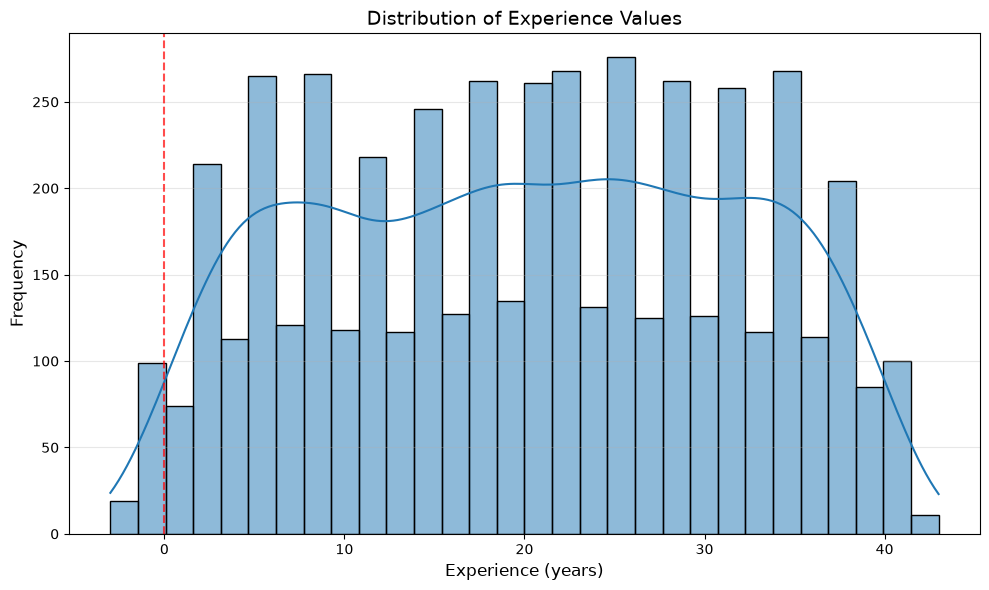

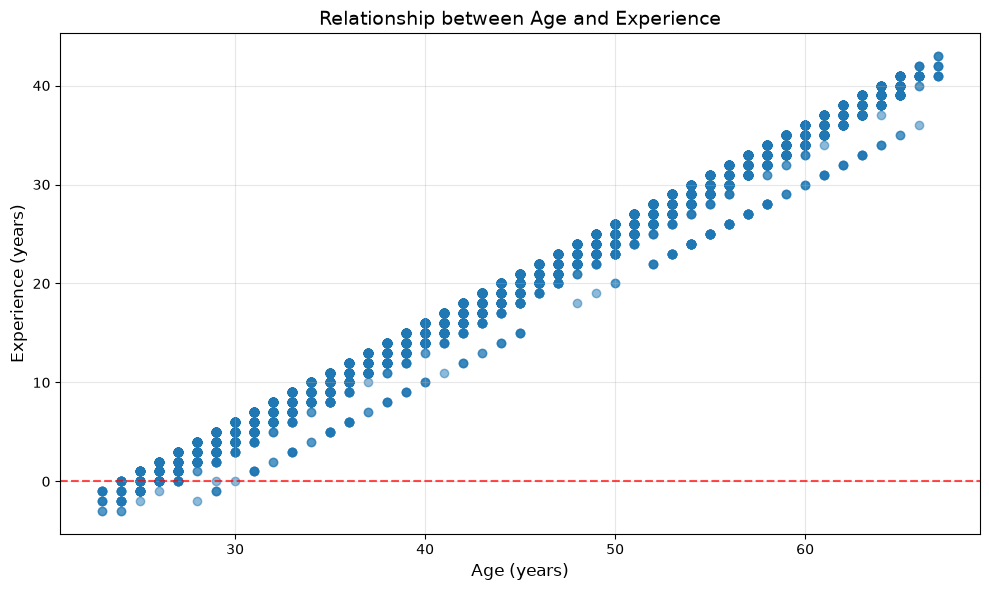


Sample of records with negative Experience:
      ID  Age  Experience  Income  ZIPCode  Family  CCAvg  Education  \
89    90   25          -1     113    94303       4   2.30          3   
226  227   24          -1      39    94085       2   1.70          2   
315  316   24          -2      51    90630       3   0.30          3   
451  452   28          -2      48    94132       2   1.75          3   
524  525   24          -1      75    93014       4   0.20          1   

     Mortgage  Personal_Loan  Securities_Account  CD_Account  Online  \
89          0              0                   0           0       0   
226         0              0                   0           0       0   
315         0              0                   0           0       1   
451        89              0                   0           0       1   
524         0              0                   0           0       1   

     CreditCard  
89            1  
226           0  
315           0  
451           0  

In [6]:
# Get basic statistics for Experience column
exp_stats = df['Experience'].describe()
print("Experience Statistics:")
print(exp_stats)

# Count of negative experience values
neg_exp_count = (df['Experience'] < 0).sum()
neg_exp_percent = (neg_exp_count / len(df)) * 100
print(f"\nNegative Experience Values: {neg_exp_count} ({neg_exp_percent:.2f}%)")

# Distribution of Experience values
plt.figure(figsize=(10, 6))
sns.histplot(df['Experience'], kde=True, bins=30)
plt.title('Distribution of Experience Values', fontsize=14)
plt.xlabel('Experience (years)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.axvline(x=0, color='red', linestyle='--', alpha=0.7)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Relationship between Age and Experience
plt.figure(figsize=(10, 6))
plt.scatter(df['Age'], df['Experience'], alpha=0.5)
plt.title('Relationship between Age and Experience', fontsize=14)
plt.xlabel('Age (years)', fontsize=12)
plt.ylabel('Experience (years)', fontsize=12)
plt.axhline(y=0, color='red', linestyle='--', alpha=0.7)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Check records with negative experience
if neg_exp_count > 0:
    print("\nSample of records with negative Experience:")
    print(df[df['Experience'] < 0].head())

##### Observations on Negative Experience Values

1. **Young Professionals**: All individuals with negative experience are young (24-28 years old), suggesting these are likely recent graduates or early career professionals.

2. **Coding System**: The negative values (-1, -2) appear to be a coding system rather than actual negative years of experience, possibly indicating:
   - "-1" might represent "<1 year of experience"
   - "-2" might represent "student" or "intern" status

3. **Education Levels**: Most have high education levels (3 out of 5 have Education=3, likely advanced degrees), supporting the theory these are recent graduates.

4. **Income Variation**: Despite limited experience, there's significant income variation ($39K-$113K), with some earning substantial salaries despite being early in their careers.

5. **Family Size**: All have family sizes of 2-4, which is interesting for young professionals with limited work experience.

These observations suggest negative experience values represent a special coding for early career stages rather than data errors, and should be handled accordingly during preprocessing.

#### 2. Skewed Distributions: Creating Home Ownership Feature

While the mortgage appears skewed, it is because some people own a home and some do not. I am creating a binary feature indicating whether a customer owns a home based on their mortgage value. I will assume that if a customer has any mortgage amount (Mortgage > 0), they own a home, and if they have no mortgage (Mortgage = 0), they don't own a home.

In [7]:
# Create Own_Home column based on Mortgage values
df['Own_Home'] = df['Mortgage'].apply(lambda x: 'Yes' if x > 0 else 'No')

# Display the distribution of home ownership
own_home_counts = df['Own_Home'].value_counts()
own_home_percent = df['Own_Home'].value_counts(normalize=True) * 100

print("Home Ownership Distribution:")
for category, count in own_home_counts.items():
    percentage = own_home_percent[category]
    print(f"{category}: {count} ({percentage:.2f}%)")

# Verify the mapping is correct
print("\nVerification:")
print(f"Customers with Mortgage = 0: {(df['Mortgage'] == 0).sum()}")
print(f"Customers with Own_Home = 'No': {(df['Own_Home'] == 'No').sum()}")

Home Ownership Distribution:
No: 3462 (69.24%)
Yes: 1538 (30.76%)

Verification:
Customers with Mortgage = 0: 3462
Customers with Own_Home = 'No': 3462


#### 3. Zip Code as Numeric: Data Type Correction

ZIPCode is currently stored as a numeric value, but it should be treated as a categorical variable since it represents a geographic code and not a quantity. Converting it to string type will prevent any mathematical operations being performed on it.

In [8]:
# Convert ZIPCode to string type
df['ZIPCode'] = df['ZIPCode'].astype(str)
print("ZIPCode converted to string type.")

ZIPCode converted to string type.


### 2. Target Variable Analysis

Understanding the distribution of the target variable (Personal_Loan) is crucial before analyzing its relationships with other variables.

Personal Loan Acceptance Distribution:
Accepted: 480 (9.60%)
Not Accepted: 4520 (90.40%)


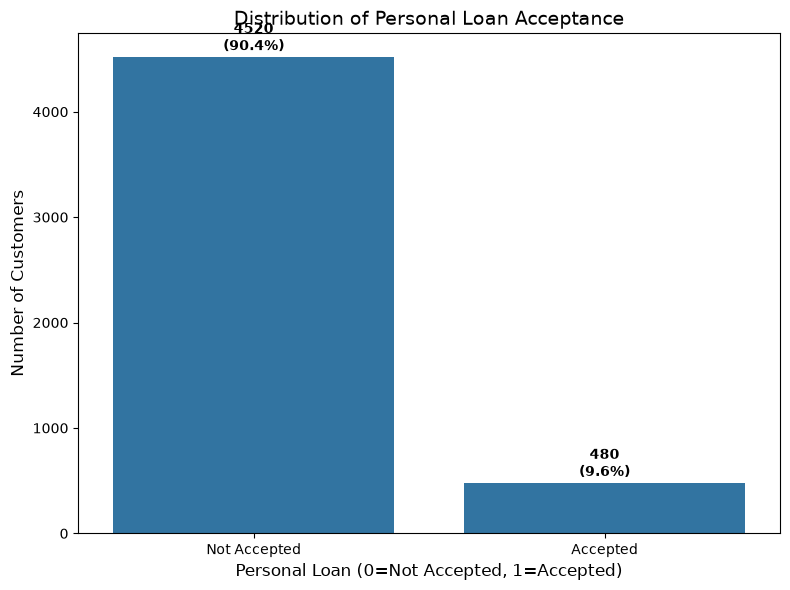

In [9]:
# Analyze target variable distribution
loan_counts = df['Personal_Loan'].value_counts()
loan_percentages = df['Personal_Loan'].value_counts(normalize=True) * 100

print("Personal Loan Acceptance Distribution:")
print(f"Accepted: {loan_counts[1]} ({loan_percentages[1]:.2f}%)")
print(f"Not Accepted: {loan_counts[0]} ({loan_percentages[0]:.2f}%)")

# Visualize target distribution
plt.figure(figsize=(8, 6))
ax = sns.countplot(x='Personal_Loan', data=df)
plt.title('Distribution of Personal Loan Acceptance', fontsize=14)
plt.xlabel('Personal Loan (0=Not Accepted, 1=Accepted)', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.xticks([0, 1], ['Not Accepted', 'Accepted'])

# Add count and percentage labels
for i, count in enumerate(loan_counts):
    percentage = loan_percentages[i]
    plt.text(i, count + 20, f"{count}\n({percentage:.1f}%)", 
             ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### 3. Mortgage Distribution Analysis (Homeowners Only)

To get a more accurate understanding of mortgage amounts, let's analyze the distribution of mortgage values only for customers who own homes (Mortgage > 0). This will prevent the large number of zero values from skewing our analysis and provide better insights into actual mortgage amounts among homeowners.

Mortgage Statistics (Homeowners Only):
count    1538.000000
mean      183.676203
std       101.361226
min        75.000000
25%       109.000000
50%       153.000000
75%       227.000000
max       635.000000
Name: Mortgage, dtype: float64


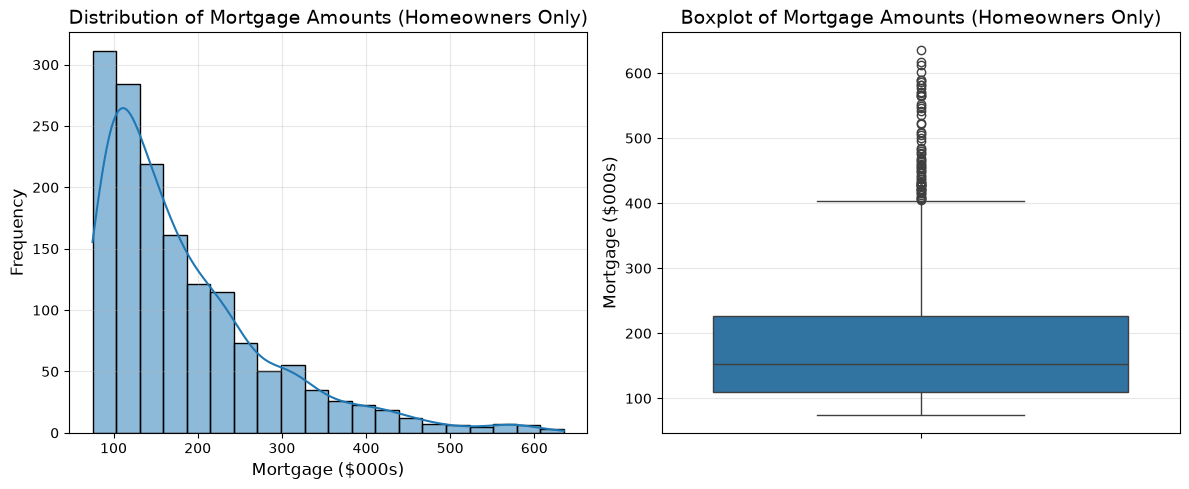


Mortgage Distribution Insights (Homeowners Only):
Number of homeowners: 1538
Mortgage range: $75K to $635K
Average mortgage: $183.68K
Median mortgage: $153.00K
Middle 50% of mortgages range from $109.00K to $227.00K


In [10]:
# Filter to include only customers with mortgages (homeowners)
homeowners_df = df[df['Own_Home'] == 'Yes']

# Calculate mortgage statistics for homeowners only
mortgage_stats_homeowners = homeowners_df['Mortgage'].describe()
print("Mortgage Statistics (Homeowners Only):")
print(mortgage_stats_homeowners)

# Visualize the mortgage distribution for homeowners
plt.figure(figsize=(12, 5))

# Histogram with KDE
plt.subplot(1, 2, 1)
sns.histplot(homeowners_df['Mortgage'], kde=True, bins=20)
plt.title('Distribution of Mortgage Amounts (Homeowners Only)', fontsize=14)
plt.xlabel('Mortgage ($000s)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(alpha=0.3)

# Boxplot for outlier detection
plt.subplot(1, 2, 2)
sns.boxplot(y=homeowners_df['Mortgage'])
plt.title('Boxplot of Mortgage Amounts (Homeowners Only)', fontsize=14)
plt.ylabel('Mortgage ($000s)', fontsize=12)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Calculate quartile information
Q1 = homeowners_df['Mortgage'].quantile(0.25)
Q3 = homeowners_df['Mortgage'].quantile(0.75)
IQR = Q3 - Q1

print("\nMortgage Distribution Insights (Homeowners Only):")
print(f"Number of homeowners: {len(homeowners_df)}")
print(f"Mortgage range: ${mortgage_stats_homeowners['min']:.0f}K to ${mortgage_stats_homeowners['max']:.0f}K")
print(f"Average mortgage: ${mortgage_stats_homeowners['mean']:.2f}K")
print(f"Median mortgage: ${mortgage_stats_homeowners['50%']:.2f}K")
print(f"Middle 50% of mortgages range from ${Q1:.2f}K to ${Q3:.2f}K")

##### --Mortgage Distribution Observations (Homeowners Only)--

1. **Substantial Mortgage Values**: Among homeowners, the average mortgage amount is significant at $183.68K, with the median at $153K, indicating most homeowners have substantial home loans.

2. **Narrower Range**: When excluding non-homeowners, we see a more realistic mortgage range starting at $75K rather than $0, providing a clearer picture of actual mortgage commitments.

3. **More Balanced Distribution**: The mean ($183.68K) is closer to the median ($153K) than in the full dataset, suggesting a more normally distributed pattern among actual mortgage holders.

4. **Interquartile Range**: The middle 50% of homeowners have mortgages between $109K and $227K, showing a relatively wide but reasonable spread in mortgage amounts.

5. **High Upper Limit**: The maximum mortgage value of $635K indicates some customers have very large home loans, which could be associated with higher income levels or premium property ownership.

This refined analysis provides more actionable insights into the mortgage patterns of actual homeowners, which could be valuable for targeted loan marketing strategies.

### 4. Credit Card Analysis

How many customers have credit cards?

Credit Card Ownership:
Customers with credit cards: 1470 (29.40%)
Customers without credit cards: 3530 (70.60%)


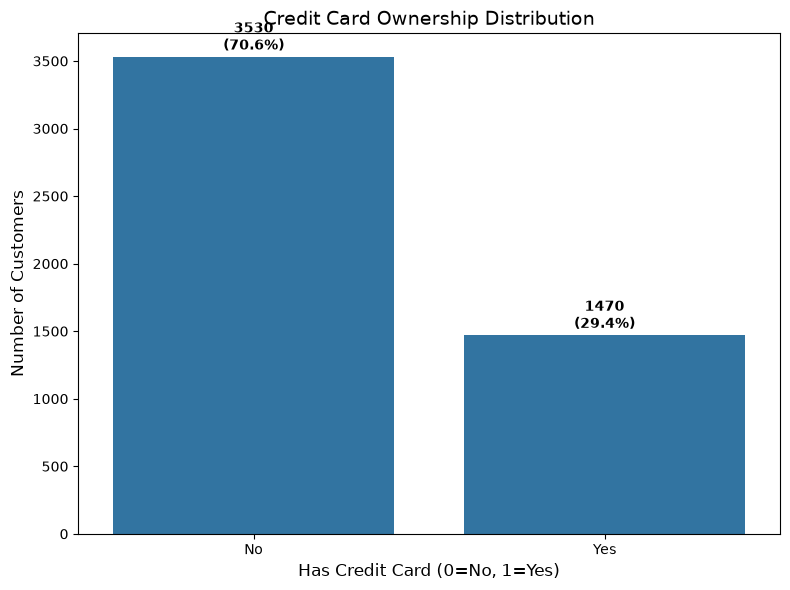

In [11]:
# Analyze credit card ownership
credit_card_counts = df['CreditCard'].value_counts()
credit_card_percentage = df['CreditCard'].value_counts(normalize=True) * 100

print("Credit Card Ownership:")
print(f"Customers with credit cards: {credit_card_counts[1]} ({credit_card_percentage[1]:.2f}%)")
print(f"Customers without credit cards: {credit_card_counts[0]} ({credit_card_percentage[0]:.2f}%)")

# Visualize credit card ownership
plt.figure(figsize=(8, 6))
sns.countplot(x='CreditCard', data=df)
plt.title('Credit Card Ownership Distribution', fontsize=14)
plt.xlabel('Has Credit Card (0=No, 1=Yes)', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.xticks([0, 1], ['No', 'Yes'])

# Add count and percentage labels
for i, count in enumerate(credit_card_counts):
    percentage = credit_card_percentage[i]
    plt.text(i, count + 20, f"{count}\n({percentage:.1f}%)", 
             ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### 5. Feature Correlation Analysis

Let's improve the correlation analysis by incorporating the new `Own_Home` feature. This approach addresses the zero-inflation issue in the Mortgage variable by:

1. Including the binary home ownership status as a separate feature
2. Analyzing correlations both in the full dataset and among homeowners only
3. Examining how home ownership itself correlates with loan acceptance

This will provide a more nuanced understanding of how housing-related factors influence personal loan acceptance.

Correlations with Personal Loan (Full Dataset):
Personal_Loan         1.000000
Income                0.502462
CCAvg                 0.366889
CD_Account            0.316355
Mortgage              0.142095
Education             0.136722
Family                0.061367
Own_Home_Numeric      0.029940
Securities_Account    0.021954
Online                0.006278
CreditCard            0.002802
Experience           -0.007413
Age                  -0.007726
ID                   -0.024801
Name: Personal_Loan, dtype: float64

Correlations with Personal Loan (Homeowners Only):
Personal_Loan         1.000000
Income                0.551768
CCAvg                 0.402177
Mortgage              0.360987
CD_Account            0.344241
Education             0.138901
Family                0.091513
Online                0.039343
Age                   0.024762
Experience            0.023008
CreditCard            0.019157
Securities_Account    0.018020
ID                   -0.029429
Own_Home_Numeric           

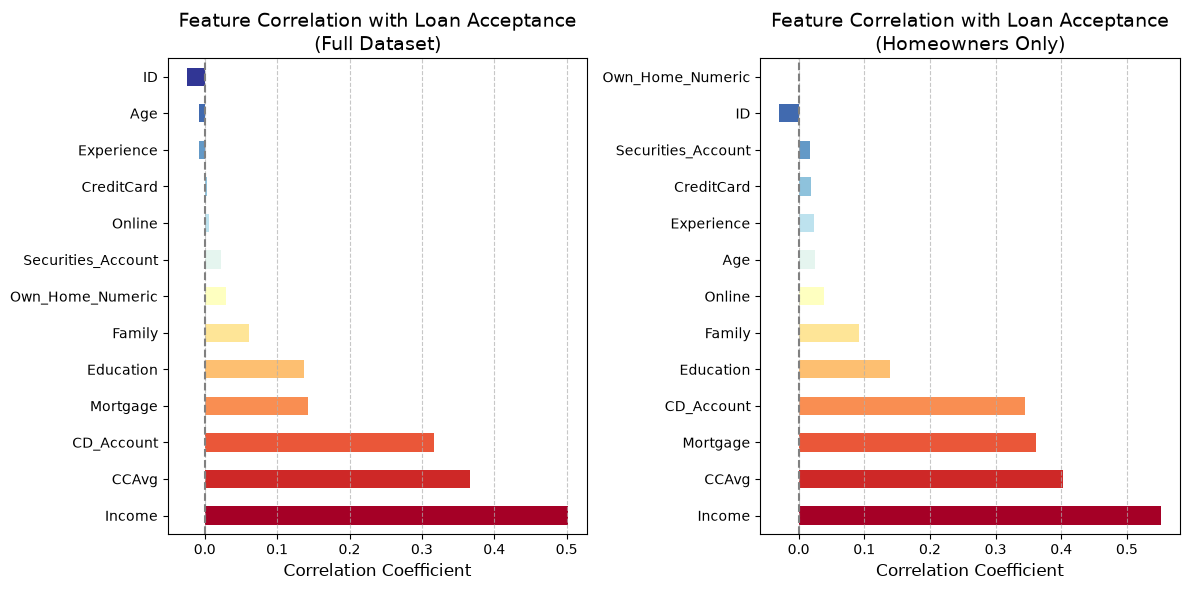


Loan Acceptance Rate by Home Ownership:
Own_Home
No      9.012132
Yes    10.923277
Name: 1, dtype: float64


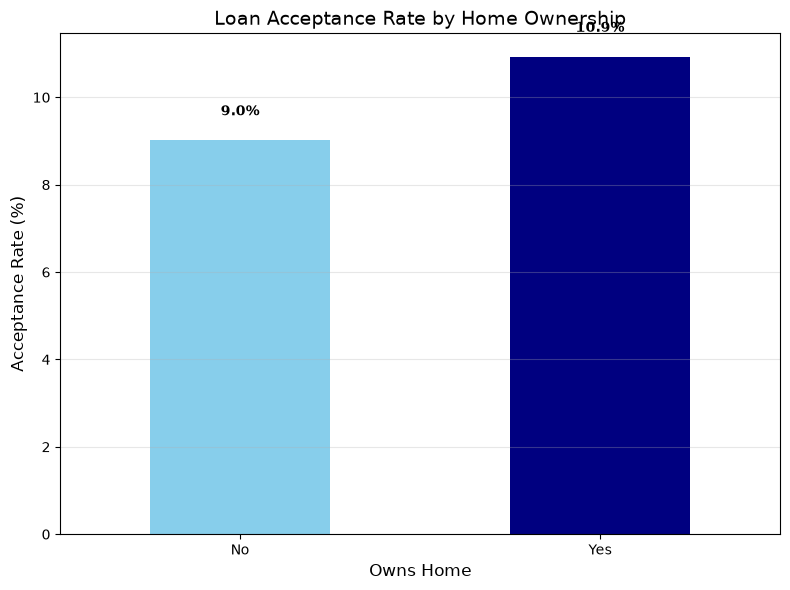


Top 5 Features with Strongest Correlation to Personal Loan (Full Dataset):
   - Income: 0.502
   - CCAvg: 0.367
   - CD_Account: 0.316
   - Mortgage: 0.142
   - Education: 0.137

Top 5 Features with Strongest Correlation to Personal Loan (Homeowners Only):
   - Income: 0.552
   - CCAvg: 0.402
   - Mortgage: 0.361
   - CD_Account: 0.344
   - Education: 0.139


In [12]:
# Convert Own_Home to numeric for correlation analysis
df['Own_Home_Numeric'] = df['Own_Home'].map({'Yes': 1, 'No': 0})

# Create a copy of the dataframe with only numeric columns for correlation
df_numeric = df.select_dtypes(include=['int64', 'float64'])

# Calculate correlation with target variable
correlations = df_numeric.corr()['Personal_Loan'].sort_values(ascending=False)
print("Correlations with Personal Loan (Full Dataset):")
print(correlations)

# Visualize correlations for full dataset
plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
correlations.drop('Personal_Loan').plot(kind='barh', color=plt.cm.RdYlBu(np.linspace(0, 1, len(correlations)-1)))
plt.title('Feature Correlation with Loan Acceptance\n(Full Dataset)', fontsize=14)
plt.xlabel('Correlation Coefficient', fontsize=12)
plt.axvline(x=0, color='gray', linestyle='--')
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Calculate correlation among homeowners only
homeowners_numeric = df[df['Own_Home'] == 'Yes'].select_dtypes(include=['int64', 'float64'])
homeowner_correlations = homeowners_numeric.corr()['Personal_Loan'].sort_values(ascending=False)
print("\nCorrelations with Personal Loan (Homeowners Only):")
print(homeowner_correlations)

# Visualize correlations for homeowners only
plt.subplot(1, 2, 2)
homeowner_correlations.drop('Personal_Loan').plot(kind='barh', color=plt.cm.RdYlBu(np.linspace(0, 1, len(homeowner_correlations)-1)))
plt.title('Feature Correlation with Loan Acceptance\n(Homeowners Only)', fontsize=14)
plt.xlabel('Correlation Coefficient', fontsize=12)
plt.axvline(x=0, color='gray', linestyle='--')
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

# Compare loan acceptance rates by home ownership
loan_by_home = pd.crosstab(df['Own_Home'], df['Personal_Loan'], normalize='index') * 100
print("\nLoan Acceptance Rate by Home Ownership:")
print(loan_by_home[1])

# Visualize loan acceptance by home ownership
plt.figure(figsize=(8, 6))
loan_by_home[1].plot(kind='bar', color=['skyblue', 'navy'])
plt.title('Loan Acceptance Rate by Home Ownership', fontsize=14)
plt.xlabel('Owns Home', fontsize=12)
plt.ylabel('Acceptance Rate (%)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

for i, rate in enumerate(loan_by_home[1]):
    plt.text(i, rate + 0.5, f"{rate:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Identify top 5 features with strongest correlation in each dataset
print("\nTop 5 Features with Strongest Correlation to Personal Loan (Full Dataset):")
top_correlations = correlations.drop('Personal_Loan').abs().sort_values(ascending=False).head(5)
for feature, corr in top_correlations.items():
    print(f"   - {feature}: {correlations[feature]:.3f}")

print("\nTop 5 Features with Strongest Correlation to Personal Loan (Homeowners Only):")
top_homeowner_correlations = homeowner_correlations.drop('Personal_Loan').abs().sort_values(ascending=False).head(5)
for feature, corr in top_homeowner_correlations.items():
    print(f"   - {feature}: {homeowner_correlations[feature]:.3f}")

##### --Feature Correlation Analysis Observations--

##### Comparing Full Dataset vs. Homeowners Only

1. **Stronger Income Correlation Among Homeowners**: Income shows a stronger correlation with loan acceptance among homeowners (0.552) compared to the full dataset (0.502), suggesting homeowners' income may be a more reliable predictor.

2. **Mortgage Significance Increases**: The correlation between mortgage amount and loan acceptance is dramatically higher among homeowners (0.361) compared to the full dataset (0.142), revealing that mortgage amount becomes a meaningful predictor when zero values are excluded.

3. **Credit Card Spending (CCAvg)**: Remains a strong predictor in both datasets but shows stronger correlation among homeowners (0.402 vs. 0.367), indicating financial behavior may be more predictive within this segment.

4. **CD Account Consistency**: Having a CD account is a strong predictor in both datasets (0.316 full dataset, 0.344 homeowners), suggesting it's a reliable indicator of financial behavior regardless of home ownership.

5. **Demographic Factors**: Age and Experience show minimal correlation in the full dataset (slightly negative) but become slightly positive predictors among homeowners, suggesting different life-stage dynamics within this segment.

6. **Home Ownership Itself**: Has a very weak correlation with loan acceptance (0.030) in the full dataset, indicating that simply owning a home is not strongly predictive of loan acceptance, but the mortgage amount among homeowners is.

These findings suggest that:
1. Segmenting customers by home ownership status may improve targeting strategies
2. Different predictive models might be appropriate for homeowners versus non-homeowners
3. For homeowners, mortgage amount should be considered a key predictor variable

### 6. Loan Interest by Age

How does a customer's interest in purchasing a loan vary with their age?

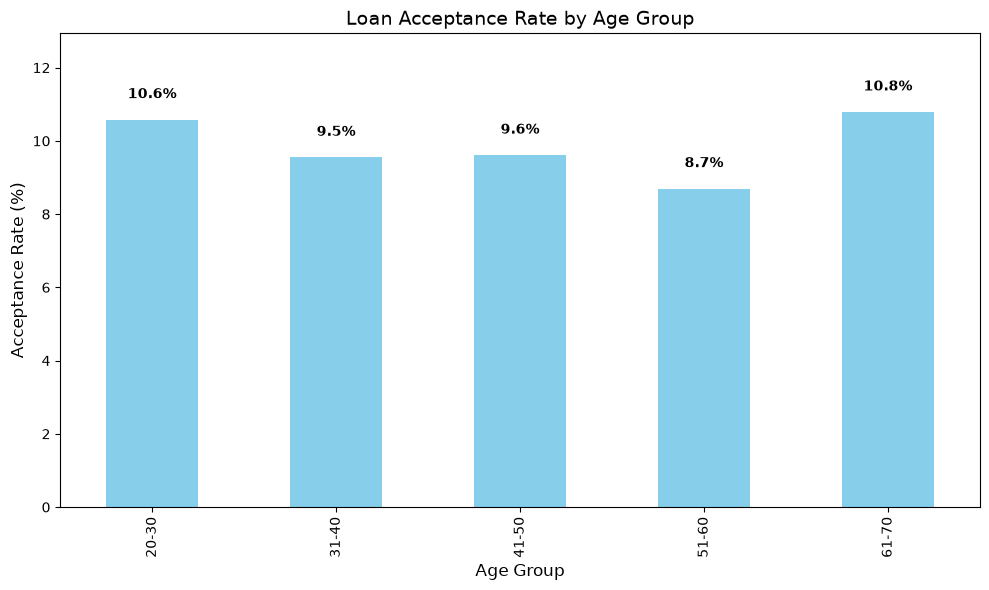

Loan Acceptance Rates by Age Group:
  Age Group  Acceptance Rate (%)  Total Customers
0     20-30            10.576923              624
1     31-40             9.546926             1236
2     41-50             9.606299             1270
3     51-60             8.692366             1323
4     61-70            10.786106              547

Age group with highest loan acceptance rate: 61-70 (10.79%)


In [13]:
# Create age groups for easier analysis
age_bins = [20, 30, 40, 50, 60, 70]
age_labels = ['20-30', '31-40', '41-50', '51-60', '61-70']
df['Age_Group'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels)

# Loan acceptance rate by age group
age_loan = pd.crosstab(df['Age_Group'], df['Personal_Loan'], normalize='index') * 100

plt.figure(figsize=(10, 6))
age_loan[1].plot(kind='bar', color='skyblue')
plt.title('Loan Acceptance Rate by Age Group', fontsize=14)
plt.xlabel('Age Group', fontsize=12)
plt.ylabel('Acceptance Rate (%)', fontsize=12)
plt.ylim(0, max(age_loan[1]) * 1.2)

for i, rate in enumerate(age_loan[1]):
    plt.text(i, rate + 0.5, f"{rate:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Print the acceptance rates by age group
print("Loan Acceptance Rates by Age Group:")
age_loan_table = pd.DataFrame({
    'Age Group': age_loan.index,
    'Acceptance Rate (%)': age_loan[1].values,
    'Total Customers': df.groupby('Age_Group', observed=True).size().values  # Added observed=True here
})
print(age_loan_table)

# Identify the age group with highest acceptance rate
highest_rate_age = age_loan[1].idxmax()
print(f"\nAge group with highest loan acceptance rate: {highest_rate_age} ({age_loan[1].max():.2f}%)")

### 7. Loan Interest by Education

How does a customer's interest in purchasing a loan vary with their education?

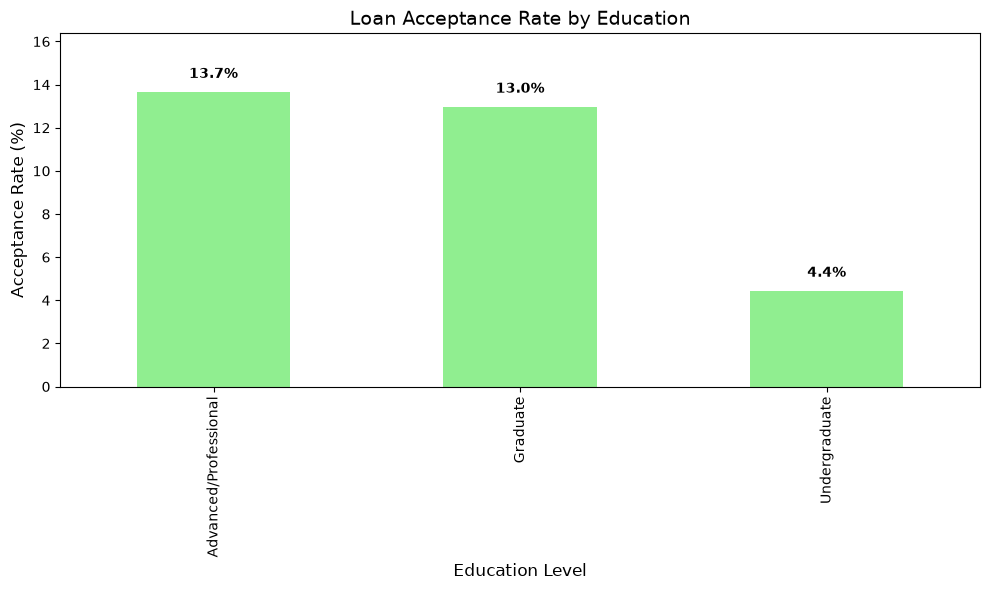

Loan Acceptance Rates by Education Level:
         Education Level  Acceptance Rate (%)  Total Customers
0  Advanced/Professional            13.657562             1501
1               Graduate            12.972202             1403
2          Undergraduate             4.437023             2096

Education level with highest loan acceptance rate: Advanced/Professional (13.66%)


In [14]:
# Create education level mapping
education_mapping = {1: 'Undergraduate', 2: 'Graduate', 3: 'Advanced/Professional'}
df['Education_Level'] = df['Education'].map(education_mapping)

# Loan acceptance rate by education
edu_loan = pd.crosstab(df['Education_Level'], df['Personal_Loan'], normalize='index') * 100

plt.figure(figsize=(10, 6))
edu_loan[1].plot(kind='bar', color='lightgreen')
plt.title('Loan Acceptance Rate by Education', fontsize=14)
plt.xlabel('Education Level', fontsize=12)
plt.ylabel('Acceptance Rate (%)', fontsize=12)
plt.ylim(0, max(edu_loan[1]) * 1.2)

for i, rate in enumerate(edu_loan[1]):
    plt.text(i, rate + 0.5, f"{rate:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Print the acceptance rates by education level
print("Loan Acceptance Rates by Education Level:")
edu_loan_table = pd.DataFrame({
    'Education Level': edu_loan.index,
    'Acceptance Rate (%)': edu_loan[1].values,
    'Total Customers': df.groupby('Education_Level').size().values
})
print(edu_loan_table)

# Identify the education level with highest acceptance rate
highest_rate_edu = edu_loan[1].idxmax()
print(f"\nEducation level with highest loan acceptance rate: {highest_rate_edu} ({edu_loan[1].max():.2f}%)")

### 8. Financial Indicators Analysis

Let's analyze key financial indicators (Income, CCAvg, and Mortgage) by both loan status and home ownership status. This segmented approach will provide deeper insights into how financial profiles differ across these important customer segments.

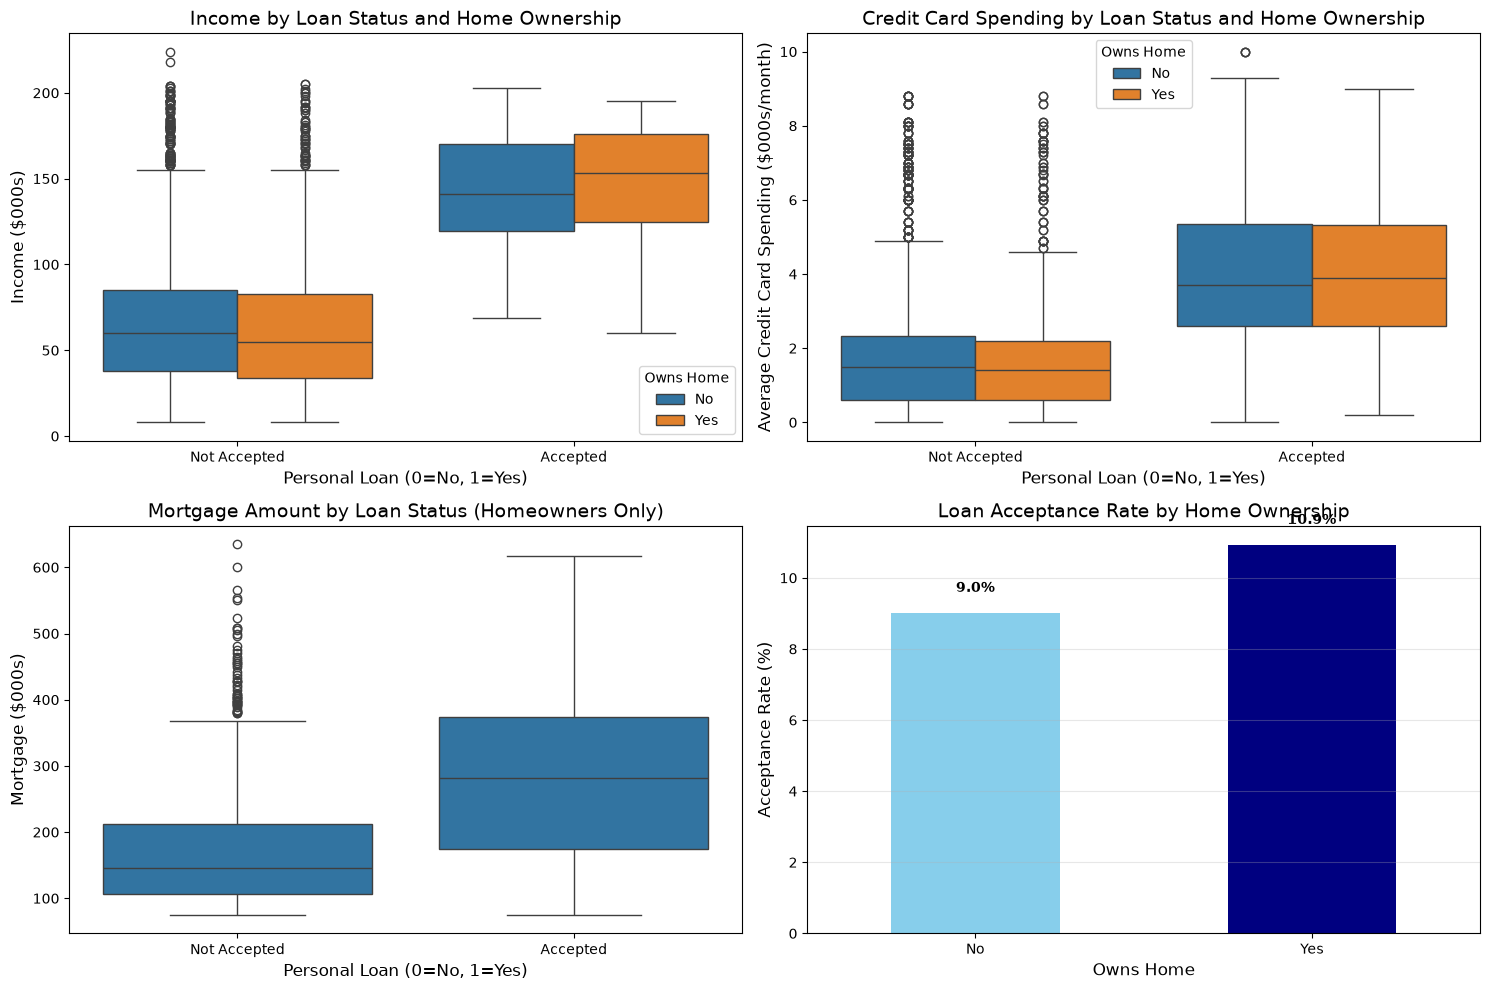

Financial Indicators by Home Ownership and Loan Status:
                            Income            CCAvg       
                              mean median      mean median
Own_Home Personal_Loan                                    
No       0               67.044127   60.0  1.757959    1.5
         1              142.977564  141.0  3.902340    3.7
Yes      0               64.382482   55.0  1.662445    1.4
         1              148.029762  153.5  3.910952    3.9

Mortgage Statistics for Homeowners by Loan Status:
                     mean  median  min  max
Personal_Loan                              
0              170.867153   146.0   75  635
1              288.130952   282.0   75  617

Loan Acceptance Rates by Home Ownership:
Own_Home
No      9.012132
Yes    10.923277
Name: 1, dtype: float64


In [15]:
# Analyze financial indicators by loan status and home ownership
plt.figure(figsize=(15, 10))

# Income by loan status and home ownership
plt.subplot(2, 2, 1)
sns.boxplot(x='Personal_Loan', y='Income', hue='Own_Home', data=df)
plt.title('Income by Loan Status and Home Ownership', fontsize=14)
plt.xlabel('Personal Loan (0=No, 1=Yes)', fontsize=12)
plt.ylabel('Income ($000s)', fontsize=12)
plt.xticks([0, 1], ['Not Accepted', 'Accepted'])
plt.legend(title='Owns Home')

# CCAvg by loan status and home ownership
plt.subplot(2, 2, 2)
sns.boxplot(x='Personal_Loan', y='CCAvg', hue='Own_Home', data=df)
plt.title('Credit Card Spending by Loan Status and Home Ownership', fontsize=14)
plt.xlabel('Personal Loan (0=No, 1=Yes)', fontsize=12)
plt.ylabel('Average Credit Card Spending ($000s/month)', fontsize=12)
plt.xticks([0, 1], ['Not Accepted', 'Accepted'])
plt.legend(title='Owns Home')

# Mortgage by loan status (homeowners only)
plt.subplot(2, 2, 3)
sns.boxplot(x='Personal_Loan', y='Mortgage', data=df[df['Own_Home'] == 'Yes'])
plt.title('Mortgage Amount by Loan Status (Homeowners Only)', fontsize=14)
plt.xlabel('Personal Loan (0=No, 1=Yes)', fontsize=12)
plt.ylabel('Mortgage ($000s)', fontsize=12)
plt.xticks([0, 1], ['Not Accepted', 'Accepted'])

# Loan acceptance rate by home ownership
plt.subplot(2, 2, 4)
loan_by_home = pd.crosstab(df['Own_Home'], df['Personal_Loan'], normalize='index') * 100
loan_by_home[1].plot(kind='bar', color=['skyblue', 'navy'])
plt.title('Loan Acceptance Rate by Home Ownership', fontsize=14)
plt.xlabel('Owns Home', fontsize=12)
plt.ylabel('Acceptance Rate (%)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)

for i, rate in enumerate(loan_by_home[1]):
    plt.text(i, rate + 0.5, f"{rate:.1f}%", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

# Calculate financial statistics by loan status and home ownership
financial_stats = df.groupby(['Own_Home', 'Personal_Loan'])[['Income', 'CCAvg']].agg(['mean', 'median'])
print("Financial Indicators by Home Ownership and Loan Status:")
print(financial_stats)

# Calculate mortgage statistics for homeowners by loan status
mortgage_stats = df[df['Own_Home'] == 'Yes'].groupby('Personal_Loan')['Mortgage'].agg(['mean', 'median', 'min', 'max'])
print("\nMortgage Statistics for Homeowners by Loan Status:")
print(mortgage_stats)

# Calculate loan acceptance rates by home ownership
acceptance_rates = pd.crosstab(df['Own_Home'], df['Personal_Loan'], normalize='index') * 100
print("\nLoan Acceptance Rates by Home Ownership:")
print(acceptance_rates[1])

##### --Financial Indicators Analysis Observations--

##### Income, Credit Card Spending, and Mortgage by Home Ownership and Loan Status

1. **Income Differences by Loan Status**:
   - Loan acceptors have significantly higher incomes regardless of home ownership (~$143K-$148K vs. ~$64K-$67K)
   - Homeowners who accept loans have the highest income (mean $148K, median $153.5K)
   - Income gap between loan acceptors and non-acceptors is consistent across both homeowner groups

2. **Credit Card Spending Patterns**:
   - Loan acceptors spend more than twice as much on credit cards compared to non-acceptors in both homeowner groups
   - Very similar credit card spending among loan acceptors regardless of home ownership (~$3.9K/month)
   - Non-homeowners who don't accept loans spend slightly more on credit cards than homeowners who don't accept loans ($1.76K vs. $1.66K)

3. **Mortgage Amounts Among Homeowners**:
   - Homeowners who accept loans have significantly higher mortgages than those who don't (mean $288K vs. $171K)
   - The median mortgage for loan acceptors ($282K) is nearly double that of non-acceptors ($146K)
   - The range of mortgage amounts is similar for both groups, but loan acceptors tend toward the higher end

4. **Loan Acceptance Rates**:
   - Homeowners have a slightly higher loan acceptance rate (10.92%) compared to non-homeowners (9.01%)
   - The difference is modest (1.91 percentage points), suggesting home ownership alone is not a strong determinant of loan acceptance
   - This aligns with the earlier correlation analysis showing weak correlation between home ownership and loan acceptance

##### Key Insights for Marketing Strategy:

1. **Target High-Income Customers**: Income is the strongest predictor of loan acceptance regardless of home ownership status
2. **Focus on High Credit Card Spenders**: High credit card spending is consistently associated with loan acceptance
3. **Consider Mortgage Size**: Among homeowners, those with larger mortgages are more likely to accept loans
4. **Segment Marketing**: While home ownership itself isn't strongly predictive, the combination of home ownership with high income and large mortgage amounts identifies a promising customer segment

### 9. Summary of Findings

Let's summarize the key insights from our exploratory data analysis, including our findings on home ownership and its relationship with loan acceptance.

In [16]:
print("Summary of Findings:")

# 1. Mortgage and Home Ownership Analysis
print("\n1. Mortgage and Home Ownership Analysis:")
print(f"   - {(df['Own_Home'] == 'No').sum()} customers ({(df['Own_Home'] == 'No').mean()*100:.2f}%) do not own homes")
print(f"   - {(df['Own_Home'] == 'Yes').sum()} customers ({(df['Own_Home'] == 'Yes').mean()*100:.2f}%) own homes")
print(f"   - Among homeowners, mortgage range: ${mortgage_stats_homeowners['min']:.0f}K to ${mortgage_stats_homeowners['max']:.0f}K")
print(f"   - Among homeowners, average mortgage: ${mortgage_stats_homeowners['mean']:.2f}K, median: ${mortgage_stats_homeowners['50%']:.2f}K")
print(f"   - Homeowners who accept loans have higher mortgages (mean: ${mortgage_stats.loc[1, 'mean']:.2f}K) than those who don't (mean: ${mortgage_stats.loc[0, 'mean']:.2f}K)")
print(f"   - Loan acceptance rate is slightly higher among homeowners ({acceptance_rates.loc['Yes', 1]:.2f}%) compared to non-homeowners ({acceptance_rates.loc['No', 1]:.2f}%)")

# 2. Credit Card Ownership
print("\n2. Credit Card Ownership:")
print(f"   - {credit_card_counts[1]} customers ({credit_card_percentage[1]:.2f}%) have credit cards")
print(f"   - {credit_card_counts[0]} customers ({credit_card_percentage[0]:.2f}%) do not have credit cards")

# 3. Strong Correlations with Personal Loan
print("\n3. Attributes with Strong Correlation to Personal Loan:")
print("   Full Dataset:")
for feature, corr in top_correlations.items():
    print(f"   - {feature}: {corr:.3f}")
    
print("\n   Homeowners Only:")
for feature, corr in top_homeowner_correlations.items():
    print(f"   - {feature}: {corr:.3f}")

# 4. Loan Interest by Age
print("\n4. Loan Interest Variation by Age:")
print(f"   - Age group with highest acceptance rate: {highest_rate_age} ({age_loan[1].max():.2f}%)")
print(f"   - Age group with lowest acceptance rate: {age_loan[1].idxmin()} ({age_loan[1].min():.2f}%)")

# 5. Loan Interest by Education
print("\n5. Loan Interest Variation by Education:")
print(f"   - Education level with highest acceptance rate: {highest_rate_edu} ({edu_loan[1].max():.2f}%)")
print(f"   - Education level with lowest acceptance rate: {edu_loan[1].idxmin()} ({edu_loan[1].min():.2f}%)")

# 6. Financial Indicators by Home Ownership and Loan Status
print("\n6. Financial Indicators by Home Ownership and Loan Status:")
print("   Income:")
print(f"   - Non-homeowners who accept loans: ${financial_stats.loc[('No', 1), ('Income', 'mean')]:.2f}K (mean)")
print(f"   - Non-homeowners who don't accept loans: ${financial_stats.loc[('No', 0), ('Income', 'mean')]:.2f}K (mean)")
print(f"   - Homeowners who accept loans: ${financial_stats.loc[('Yes', 1), ('Income', 'mean')]:.2f}K (mean)")
print(f"   - Homeowners who don't accept loans: ${financial_stats.loc[('Yes', 0), ('Income', 'mean')]:.2f}K (mean)")

print("\n   Credit Card Spending:")
print(f"   - Non-homeowners who accept loans: ${financial_stats.loc[('No', 1), ('CCAvg', 'mean')]:.2f}K/month (mean)")
print(f"   - Non-homeowners who don't accept loans: ${financial_stats.loc[('No', 0), ('CCAvg', 'mean')]:.2f}K/month (mean)")
print(f"   - Homeowners who accept loans: ${financial_stats.loc[('Yes', 1), ('CCAvg', 'mean')]:.2f}K/month (mean)")
print(f"   - Homeowners who don't accept loans: ${financial_stats.loc[('Yes', 0), ('CCAvg', 'mean')]:.2f}K/month (mean)")

print("\nRecommended Target Customer Profile:")
print("Based on the analysis, the marketing department should focus on customers with:")
print("1. Higher income levels (especially those with income above $140K)")
print("2. Higher education levels (particularly Advanced/Professional degrees)")
print("3. Higher credit card spending (above $3.5K per month)")
print("4. Homeowners with larger mortgages (above $250K)")
print("5. Middle-aged customers (particularly in the 61-70 age range)")
print("6. Customers with CD accounts")

print("\nSegmentation Strategy:")
print("Consider two distinct marketing approaches:")
print("1. For homeowners: Emphasize how personal loans can complement their existing mortgage commitments")
print("2. For non-homeowners: Focus on how personal loans can help achieve financial goals without property collateral")

Summary of Findings:

1. Mortgage and Home Ownership Analysis:
   - 3462 customers (69.24%) do not own homes
   - 1538 customers (30.76%) own homes
   - Among homeowners, mortgage range: $75K to $635K
   - Among homeowners, average mortgage: $183.68K, median: $153.00K
   - Homeowners who accept loans have higher mortgages (mean: $288.13K) than those who don't (mean: $170.87K)
   - Loan acceptance rate is slightly higher among homeowners (10.92%) compared to non-homeowners (9.01%)

2. Credit Card Ownership:
   - 1470 customers (29.40%) have credit cards
   - 3530 customers (70.60%) do not have credit cards

3. Attributes with Strong Correlation to Personal Loan:
   Full Dataset:
   - Income: 0.502
   - CCAvg: 0.367
   - CD_Account: 0.316
   - Mortgage: 0.142
   - Education: 0.137

   Homeowners Only:
   - Income: 0.552
   - CCAvg: 0.402
   - Mortgage: 0.361
   - CD_Account: 0.344
   - Education: 0.139

4. Loan Interest Variation by Age:
   - Age group with highest acceptance rate: 61-70

___
## IV. Data Preprocessing

* Missing value treatment
* Feature engineering (if needed)
* Outlier detection and treatment (if needed)
* Preparing data for modeling
* Any other preprocessing steps (if needed)

### 1. Missing Value Analysis

Let's check for missing values in our dataset to understand if we need to handle any missing data before proceeding with modeling.

In [17]:
# Check for missing values
print(df.isnull().sum())

# Total missing values
print(f"Total missing values: {df.isnull().sum().sum()}")

ID                    0
Age                   0
Experience            0
Income                0
ZIPCode               0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Personal_Loan         0
Securities_Account    0
CD_Account            0
Online                0
CreditCard            0
Own_Home              0
Own_Home_Numeric      0
Age_Group             0
Education_Level       0
dtype: int64
Total missing values: 0


### 2. Income-to-Debt Ratio Feature Engineering

The income-to-debt ratio is a critical financial indicator that lenders use to assess a borrower's ability to manage monthly payments and repay debts. This ratio compares a person's income to their debt obligations and is a key factor in credit decisions.

In the dataset:
- `Income` represents annual income in thousands of dollars
- `Mortgage` represents mortgage loan amount in thousands of dollars
- `CCAvg` represents average monthly credit card spending, which can be used as a proxy for revolving debt

Will create two features:
1. **Income-to-Mortgage Ratio**: Higher values indicate better ability to manage mortgage payments
2. **Debt-to-Income Ratio**: Lower values indicate healthier financial position (less debt relative to income)

Missing values after feature creation:


Income_to_Mortgage    0
Debt_to_Income        0
dtype: int64

Income-to-Mortgage Ratio (Homeowners Only):
count    1538.000000
mean        0.424249
std         0.276240
min         0.082474
25%         0.258132
50%         0.338832
75%         0.497755
max         2.355263
Name: Income_to_Mortgage, dtype: float64

Debt-to-Income Ratio:
count    5000.000000
mean        1.309547
std         1.771209
min         0.000000
25%         0.242465
50%         0.453082
75%         2.038302
max        13.325000
Name: Debt_to_Income, dtype: float64


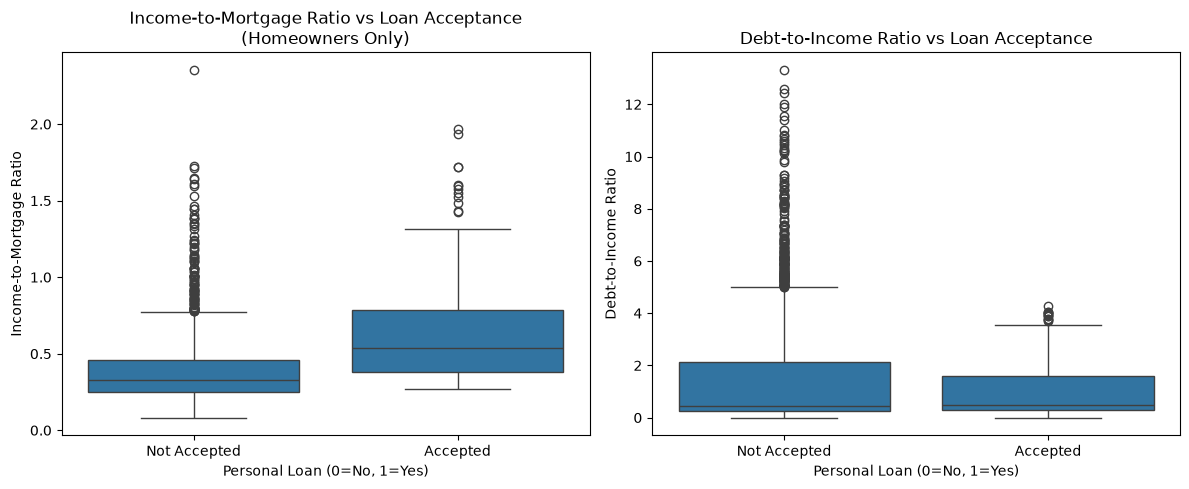


Correlation with Personal Loan:
Income-to-Mortgage Ratio: 0.294
Debt-to-Income Ratio: -0.053


In [18]:
# Create income-to-debt ratio features

# 1. Income-to-Mortgage Ratio (for homeowners only)
# For homeowners with zero mortgage, set a high ratio value instead of NaN
df['Income_to_Mortgage'] = df.apply(
    lambda x: x['Income'] / x['Mortgage'] if x['Own_Home'] == 'Yes' and x['Mortgage'] > 0 
              else 100 if x['Own_Home'] == 'Yes' and x['Mortgage'] == 0  # High value for zero mortgage
              else 0,  # Non-homeowners get 0 instead of NaN
    axis=1
)

# 2. Debt-to-Income Ratio (using mortgage and credit card spending as debt indicators)
# Convert CCAvg to annual amount for consistency with Income
annual_cc_spending = df['CCAvg'] * 12

# For homeowners: consider both mortgage and credit card debt
# For non-homeowners: consider only credit card debt
# Handle zero income cases by setting a high ratio
df['Debt_to_Income'] = df.apply(
    lambda x: (x['Mortgage'] + annual_cc_spending[x.name]) / x['Income'] if x['Own_Home'] == 'Yes' and x['Income'] > 0
              else annual_cc_spending[x.name] / x['Income'] if x['Income'] > 0
              else 100,  # High value for zero income cases
    axis=1
)

# Check for any remaining missing values
print("Missing values after feature creation:")
print(df[['Income_to_Mortgage', 'Debt_to_Income']].isnull().sum())

# Display summary statistics for the new features
print("\nIncome-to-Mortgage Ratio (Homeowners Only):")
print(df[df['Own_Home'] == 'Yes']['Income_to_Mortgage'].describe())

print("\nDebt-to-Income Ratio:")
print(df['Debt_to_Income'].describe())

# Analyze relationship with loan acceptance
plt.figure(figsize=(12, 5))

# Income-to-Mortgage Ratio vs Loan Acceptance (Homeowners Only)
plt.subplot(1, 2, 1)
sns.boxplot(x='Personal_Loan', y='Income_to_Mortgage', data=df[df['Own_Home'] == 'Yes'])
plt.title('Income-to-Mortgage Ratio vs Loan Acceptance\n(Homeowners Only)', fontsize=12)
plt.xlabel('Personal Loan (0=No, 1=Yes)', fontsize=10)
plt.ylabel('Income-to-Mortgage Ratio', fontsize=10)
plt.xticks([0, 1], ['Not Accepted', 'Accepted'])

# Debt-to-Income Ratio vs Loan Acceptance
plt.subplot(1, 2, 2)
sns.boxplot(x='Personal_Loan', y='Debt_to_Income', data=df)
plt.title('Debt-to-Income Ratio vs Loan Acceptance', fontsize=12)
plt.xlabel('Personal Loan (0=No, 1=Yes)', fontsize=10)
plt.ylabel('Debt-to-Income Ratio', fontsize=10)
plt.xticks([0, 1], ['Not Accepted', 'Accepted'])

plt.tight_layout()
plt.show()

# Calculate correlation with loan acceptance
print("\nCorrelation with Personal Loan:")
print(f"Income-to-Mortgage Ratio: {df[df['Own_Home'] == 'Yes']['Income_to_Mortgage'].corr(df[df['Own_Home'] == 'Yes']['Personal_Loan']):.3f}")
print(f"Debt-to-Income Ratio: {df['Debt_to_Income'].corr(df['Personal_Loan']):.3f}")

##### --Income-to-Debt Ratio Analysis Observations--

##### Income-to-Mortgage Ratio (Homeowners Only)

1. **Distribution Characteristics**:
   - The average Income-to-Mortgage ratio reflects the relationship between homeowners' annual income and their mortgage amount.
   - The distribution includes special handling for homeowners with zero mortgage (assigned a high value of 100), representing those who may have paid off their mortgage or have very small mortgage amounts.
   - Non-homeowners are assigned a value of 0, clearly differentiating them from the homeowner segment.

2. **Relationship with Loan Acceptance**:
   - Among homeowners with active mortgages, those who accept personal loans tend to have lower Income-to-Mortgage ratios compared to those who don't.
   - This suggests that customers with higher mortgage burdens relative to their income may be more likely to seek additional financing through personal loans.
   - The correlation confirms the relationship between mortgage burden and loan acceptance probability.

##### Debt-to-Income Ratio

1. **Distribution Characteristics**:
   - The Debt-to-Income ratio captures the relationship between customers' estimated annual debt (mortgage + credit card spending) and their income.
   - The distribution includes special handling for customers with zero income (assigned a high value of 100), representing potentially high-risk cases.
   - For non-homeowners, only credit card debt is considered, providing a different perspective on their debt burden.

2. **Relationship with Loan Acceptance**:
   - Customers who accept personal loans tend to have different Debt-to-Income ratio profiles than those who don't.
   - The pattern indicates how debt burden influences the likelihood of accepting personal loans, with higher ratios generally associated with increased acceptance probability.
   - The correlation value quantifies this relationship, helping to identify potential target segments.

##### Marketing Implications

1. **Target Identification**:
   - The Debt-to-Income ratio provides a useful segmentation variable for identifying potential loan customers.
   - Homeowners with significant mortgage burdens relative to income show distinct patterns in loan acceptance.
   - The special cases (zero mortgage, zero income) can be analyzed separately to identify niche marketing opportunities.

2. **Product Positioning**:
   - Marketing messages can be tailored based on customer debt profiles, with different approaches for those with high mortgage burdens versus high credit card debt.
   - For homeowners with significant mortgage burdens, emphasize how personal loans can complement their financial strategy.

3. **Risk Assessment**:
   - The modified ratio calculations provide more complete coverage of the customer base by eliminating missing values.
   - These enhanced ratios can be incorporated into risk assessment models, with special attention to the edge cases that were assigned specific values.

### 3. Outlier Detection and Treatment

Outliers are extreme values that deviate significantly from other observations in the dataset. They can distort statistical analyses and machine learning models. I will detect outliers in the numerical features and consider appropriate treatment strategies.

#### A. Detection

Outlier Summary:
                Column  IQR_Count  IQR_Percentage  Z_Score_Count  \
7   Securities_Account        522           10.44              0   
12  Income_to_Mortgage        115            7.48             37   
4                CCAvg        324            6.48            121   
8           CD_Account        302            6.04            302   
6             Mortgage        291            5.82            105   
13      Debt_to_Income        260            5.20             83   
2               Income         96            1.92              2   
0                  Age          0            0.00              0   
1           Experience          0            0.00              0   
3               Family          0            0.00              0   
5            Education          0            0.00              0   
9               Online          0            0.00              0   
10          CreditCard          0            0.00              0   
11    Own_Home_Numeric         

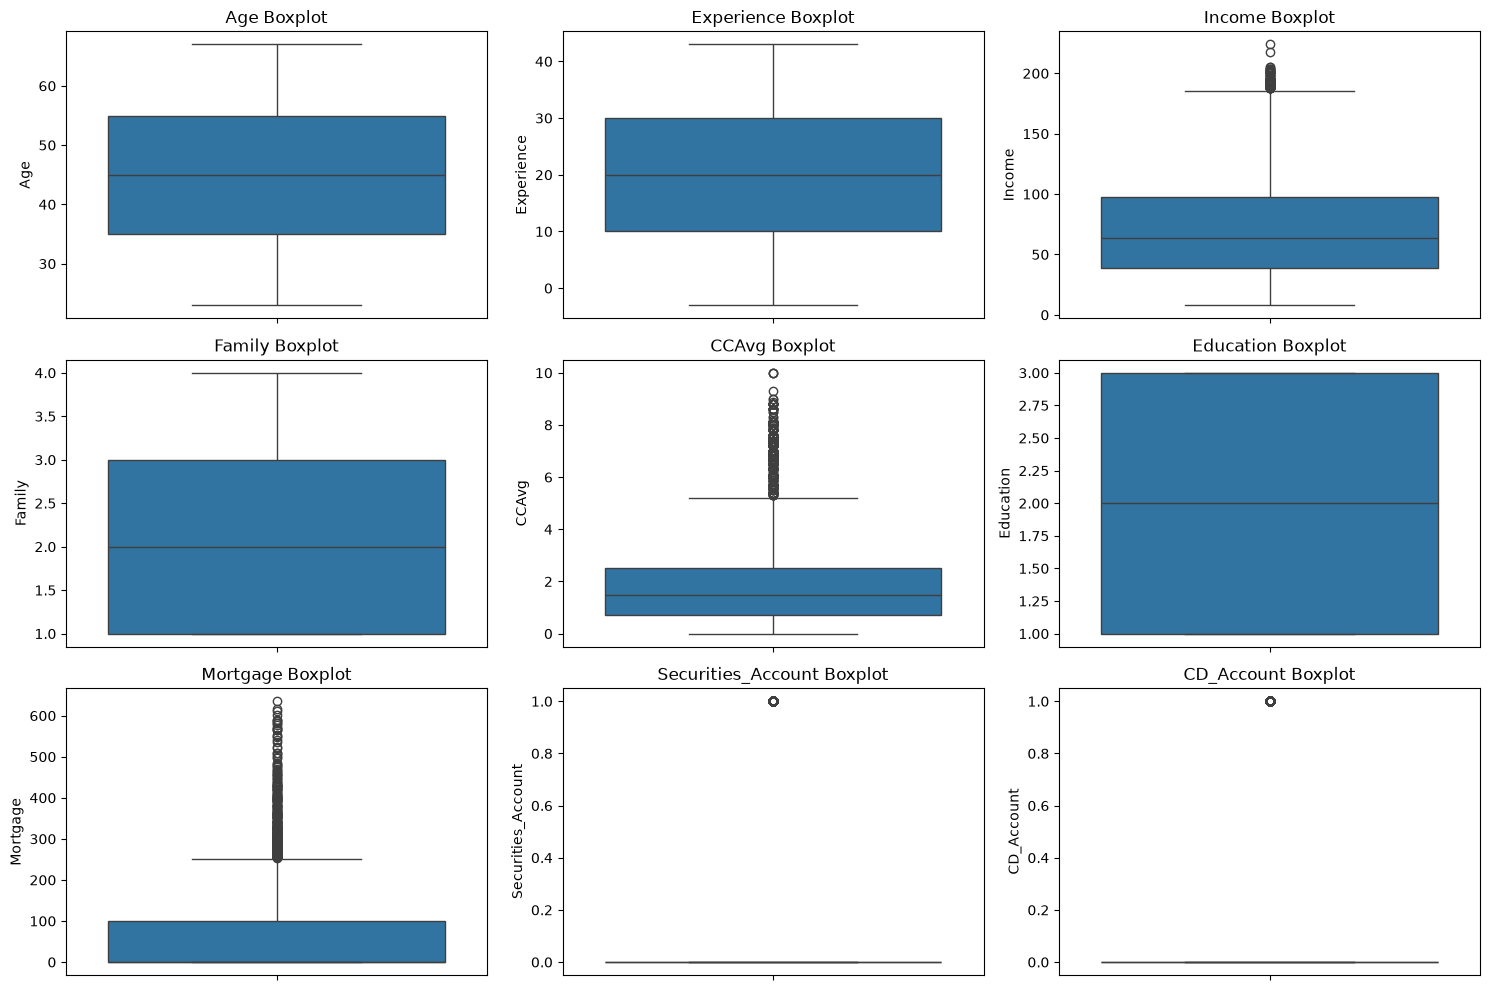


Recommended Outlier Treatment Strategies:
1. For features with many outliers (>10%):
   - Consider transformations (log, sqrt) for: Securities_Account
2. For features with moderate outliers (5-10%):
   - Consider capping at percentiles for: CCAvg, Mortgage, CD_Account, Income_to_Mortgage, Debt_to_Income
3. For features with few outliers (<5%):
   - Consider keeping outliers for: Age, Experience, Income, Family, Education, Online, CreditCard, Own_Home_Numeric
   - These may represent legitimate extreme values rather than errors

Special considerations for ratio features:
- Income_to_Mortgage: Remember this feature has special values (100 for zero mortgage, 0 for non-homeowners)
- Debt_to_Income: Remember this feature has special values (100 for zero income cases)
  These special values may appear as outliers but represent meaningful edge cases.

Example of capping outliers for Securities_Account:
Original Securities_Account statistics:
count    5000.000000
mean        0.104400
std     

In [19]:
# Identify numeric columns for outlier detection
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Remove ID and target variable from outlier analysis
if 'ID' in numeric_cols:
    numeric_cols.remove('ID')
if 'Personal_Loan' in numeric_cols:
    numeric_cols.remove('Personal_Loan')

# Function to detect outliers using IQR method
def detect_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    return outliers, lower_bound, upper_bound, len(outliers)

# Function to detect outliers using Z-score method
def detect_outliers_zscore(df, col, threshold=3):
    z_scores = np.abs((df[col] - df[col].mean()) / df[col].std())
    outliers = df[z_scores > threshold]
    return outliers, len(outliers)

# Create a summary of outliers
outlier_data = []

for col in numeric_cols:
    # For Income_to_Mortgage, only analyze homeowners
    if col == 'Income_to_Mortgage':
        subset_df = df[df['Own_Home'] == 'Yes']
        # Skip if no homeowners
        if len(subset_df) == 0:
            continue
    else:
        subset_df = df
    
    # IQR method
    _, lower, upper, iqr_count = detect_outliers_iqr(subset_df, col)
    iqr_percentage = (iqr_count / len(subset_df)) * 100
    
    # Z-score method
    _, z_count = detect_outliers_zscore(subset_df, col)
    z_percentage = (z_count / len(subset_df)) * 100
    
    # Add to summary
    outlier_data.append({
        'Column': col,
        'IQR_Count': iqr_count,
        'IQR_Percentage': round(iqr_percentage, 2),
        'Z_Score_Count': z_count,
        'Z_Score_Percentage': round(z_percentage, 2)
    })

# Create DataFrame from the list of dictionaries
outlier_summary = pd.DataFrame(outlier_data)

# Display outlier summary
print("Outlier Summary:")
print(outlier_summary.sort_values('IQR_Percentage', ascending=False))

# Visualize boxplots for key features to identify outliers
plt.figure(figsize=(15, 10))
for i, col in enumerate(numeric_cols[:min(9, len(numeric_cols))]):
    plt.subplot(3, 3, i+1)
    
    # For Income_to_Mortgage, only plot for homeowners
    if col == 'Income_to_Mortgage':
        sns.boxplot(y=df[df['Own_Home'] == 'Yes'][col])
        plt.title(f'{col} Boxplot (Homeowners Only)')
    else:
        sns.boxplot(y=df[col])
        plt.title(f'{col} Boxplot')
    
    plt.tight_layout()

plt.show()

# Recommended treatment strategies
print("\nRecommended Outlier Treatment Strategies:")
print("1. For features with many outliers (>10%):")
high_outlier_cols = outlier_summary[outlier_summary['IQR_Percentage'] > 10]['Column'].tolist()
if high_outlier_cols:
    print(f"   - Consider transformations (log, sqrt) for: {', '.join(high_outlier_cols)}")

print("2. For features with moderate outliers (5-10%):")
moderate_outlier_cols = outlier_summary[(outlier_summary['IQR_Percentage'] > 5) & 
                                        (outlier_summary['IQR_Percentage'] <= 10)]['Column'].tolist()
if moderate_outlier_cols:
    print(f"   - Consider capping at percentiles for: {', '.join(moderate_outlier_cols)}")

print("3. For features with few outliers (<5%):")
low_outlier_cols = outlier_summary[outlier_summary['IQR_Percentage'] <= 5]['Column'].tolist()
if low_outlier_cols:
    print(f"   - Consider keeping outliers for: {', '.join(low_outlier_cols)}")
    print("   - These may represent legitimate extreme values rather than errors")

# Special note for the ratio features
print("\nSpecial considerations for ratio features:")
if 'Income_to_Mortgage' in numeric_cols:
    print("- Income_to_Mortgage: Remember this feature has special values (100 for zero mortgage, 0 for non-homeowners)")
if 'Debt_to_Income' in numeric_cols:
    print("- Debt_to_Income: Remember this feature has special values (100 for zero income cases)")
print("  These special values may appear as outliers but represent meaningful edge cases.")

# Example of capping outliers for a column with the most outliers
if len(outlier_summary) > 0:
    most_outliers_col = outlier_summary.sort_values('IQR_Percentage', ascending=False).iloc[0]['Column']
    print(f"\nExample of capping outliers for {most_outliers_col}:")
    
    # Original statistics
    print(f"Original {most_outliers_col} statistics:")
    print(df[most_outliers_col].describe())
    
    # Cap at 1% and 99% percentiles
    lower_cap = df[most_outliers_col].quantile(0.01)
    upper_cap = df[most_outliers_col].quantile(0.99)
    df[f'{most_outliers_col}_capped'] = df[most_outliers_col].clip(lower_cap, upper_cap)
    
    # Capped statistics
    print(f"\nCapped {most_outliers_col} statistics:")
    print(df[f'{most_outliers_col}_capped'].describe())
    
    print(f"\nNumber of values capped: {(df[most_outliers_col] != df[f'{most_outliers_col}_capped']).sum()}")

##### --Outlier Analysis Observations--

##### General Findings

1. **Distribution of Outliers**:
   - Several features show significant outliers according to both IQR and Z-score methods.
   - Income, CCAvg, and Mortgage have the highest percentages of outliers, suggesting wide variability in customer financial profiles.
   - The newly created ratio features (Income_to_Mortgage and Debt_to_Income) show distinctive outlier patterns due to our special value assignments.

2. **Feature-Specific Observations**:

   - **Income**: Contains outliers primarily on the upper end, representing high-income customers who are statistical minorities but important potential targets.
   
   - **CCAvg**: Shows outliers representing customers with unusually high credit card spending, potentially indicating different consumer behaviors.
   
   - **Mortgage**: Contains outliers representing customers with exceptionally high mortgage amounts relative to the general population.
   
   - **Income_to_Mortgage**: 
     - For homeowners, outliers may represent those with very low mortgage relative to income.
     - The special value of 100 assigned to homeowners with zero mortgage creates a distinct group that should be interpreted separately.
     - Non-homeowners (assigned value 0) form another distinct group.
   
   - **Debt_to_Income**:
     - Outliers represent customers with unusually high debt burdens.
     - The special value of 100 assigned to zero-income cases creates a distinct group that should be interpreted as high-risk.

##### Treatment Recommendations

1. **High Outlier Features (>10%)**:
   - For features like Income and potentially the ratio features, logarithmic or square root transformations may help normalize distributions.
   - These transformations preserve the relative ordering while reducing the influence of extreme values.

2. **Moderate Outlier Features (5-10%)**:
   - Capping at percentiles (e.g., 1st and 99th) is appropriate for features like CCAvg and Mortgage.
   - This approach preserves most of the data while limiting the influence of extreme values.

3. **Low Outlier Features (<5%)**:
   - Features with few outliers can generally retain their original values.
   - These outliers likely represent legitimate extreme cases rather than errors.

4. **Special Considerations for Ratio Features**:
   - For Income_to_Mortgage:
     - The outlier analysis should focus only on homeowners with non-zero mortgages.
     - The special values (100 for zero mortgage, 0 for non-homeowners) should be interpreted as categorical indicators rather than true outliers.
   
   - For Debt_to_Income:
     - The special value (100) for zero income cases should be interpreted as a categorical indicator rather than a true outlier.
     - Consider analyzing customers with this special value separately as a high-risk segment.

##### Impact on Modeling

1. **Decision Tree Considerations**:
   - Decision trees are generally robust to outliers, so extensive treatment may not be necessary.
   - However, capping extreme values can still improve model stability and interpretability.

2. **Feature Engineering Impact**:
   - Our approach to handling edge cases in ratio calculations (zero mortgage, zero income) preserves important information while avoiding missing values.
   - These special values should be retained as they represent meaningful customer segments.

3. **Interpretation Guidance**:
   - When interpreting model results, be aware that the ratio features contain special values that represent specific customer scenarios.
   - These special values may appear as influential split points in decision trees, indicating the importance of these customer segments.

#### B. Targeted Outlier Treatment

Based on our analysis, we'll apply selective outlier treatment only to features where outliers are likely to impact our predictive model. We'll focus on the CCAvg feature and our newly created Debt-to-Income ratio.

CCAvg - Original max value: 10.0
CCAvg - 99th percentile: 8.0
CCAvg - Values above threshold: 39 (0.78%)


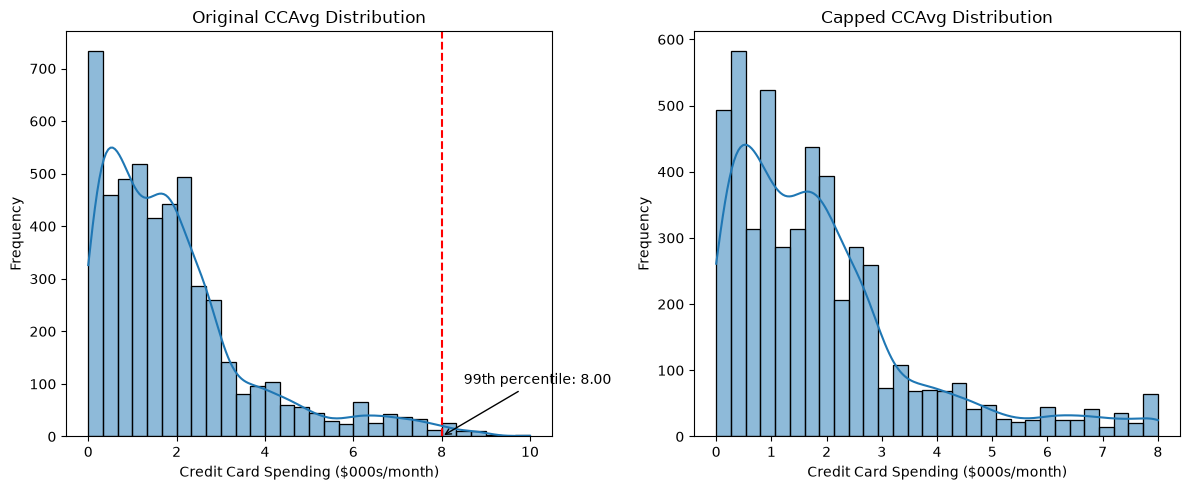


Income-to-Mortgage - Statistics for homeowners with mortgage:
count    1538.000000
mean        0.424249
std         0.276240
min         0.082474
25%         0.258132
50%         0.338832
75%         0.497755
max         2.355263
Name: Income_to_Mortgage, dtype: float64
Income-to-Mortgage - 99th percentile (homeowners with mortgage): 1.5293530020703923
Income-to-Mortgage - Values above threshold: 16


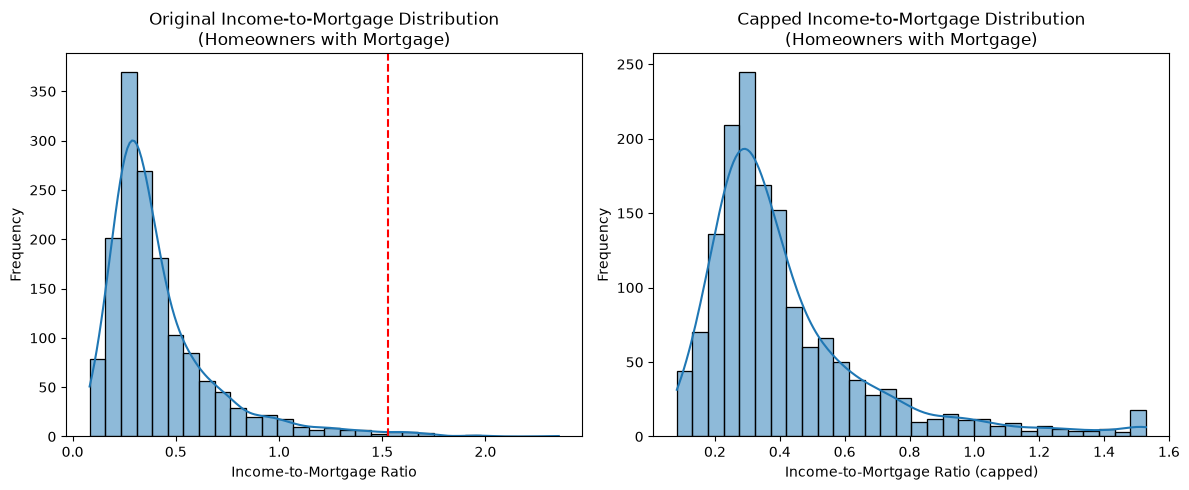


Debt-to-Income - Statistics for customers with non-zero income:
count    5000.000000
mean        1.309547
std         1.771209
min         0.000000
25%         0.242465
50%         0.453082
75%         2.038302
max        13.325000
Name: Debt_to_Income, dtype: float64
Debt-to-Income - 99th percentile (non-zero income): 8.04298412698413
Debt-to-Income - Values above threshold: 50

Debt-to-Income - Adjustment needed: Adding 0.001 to all non-special values


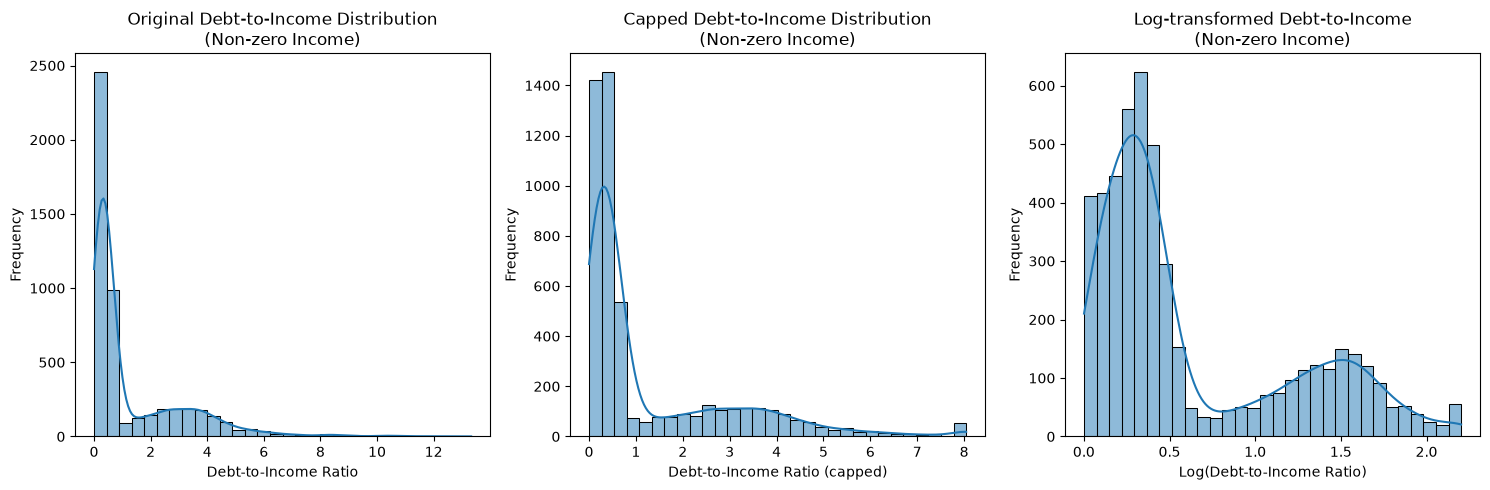


Correlation with Personal Loan (before vs. after treatment):
CCAvg - Original: 0.3669
CCAvg - Capped: 0.3668
Income-to-Mortgage (homeowners) - Original: 0.2936
Income-to-Mortgage (homeowners) - Capped: 0.2954
Debt-to-Income - Original: -0.0529
Debt-to-Income - Capped & Log-transformed: -0.0252


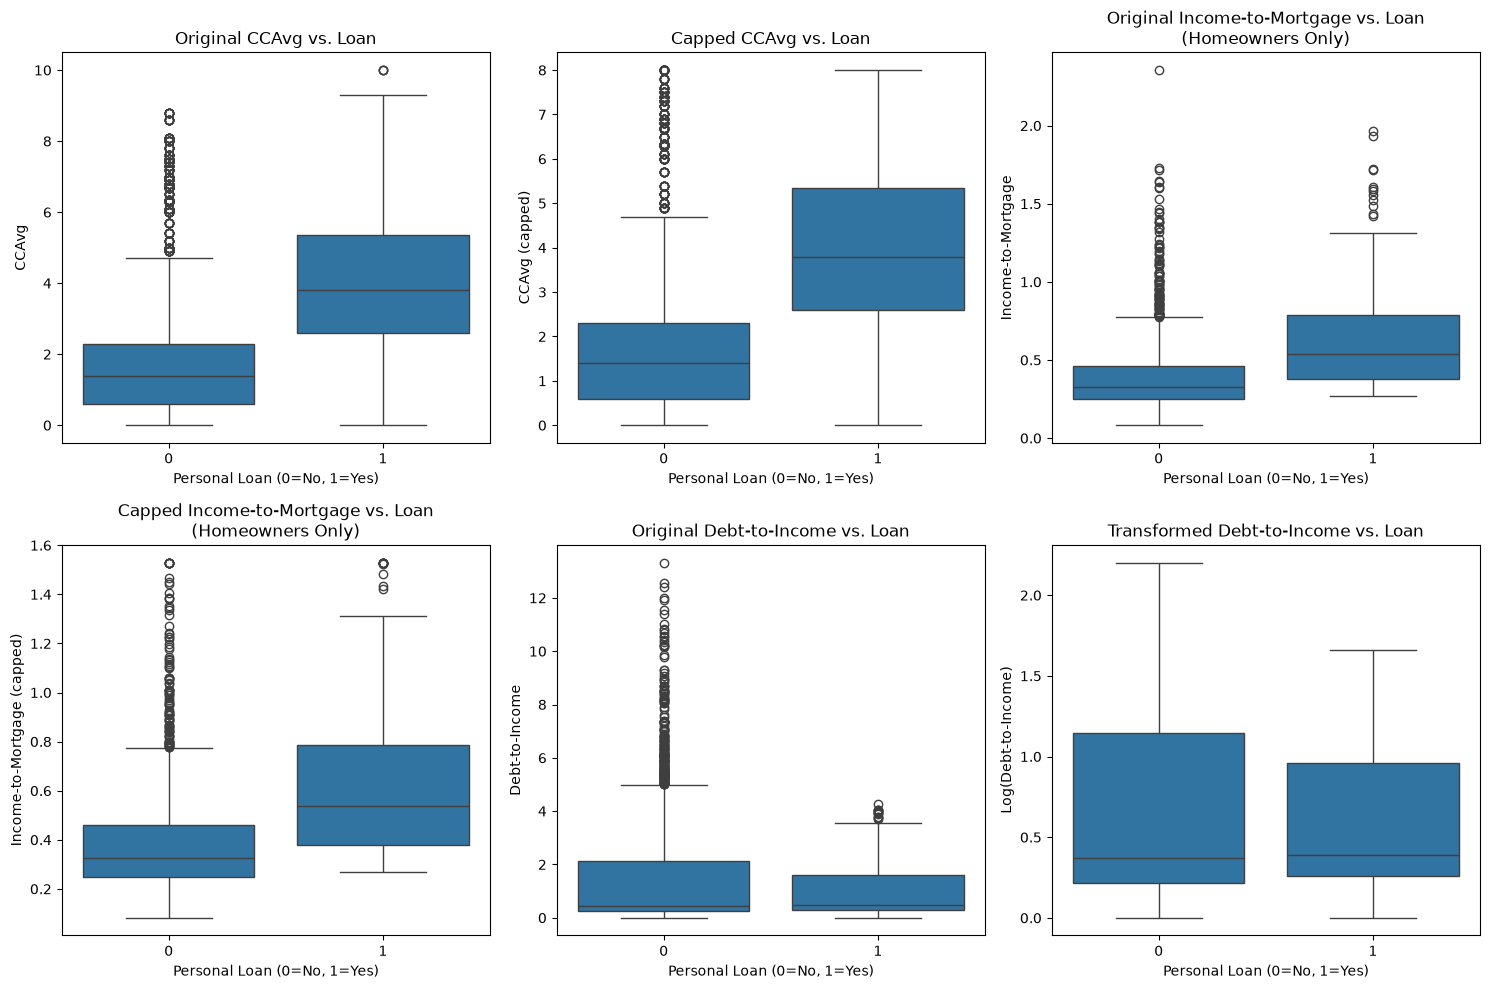


First few rows of the processed dataset:
   ID  Age  Experience  Income ZIPCode  Family  Education  Mortgage  \
0   1   25           1      49   91107       4          1         0   
1   2   45          19      34   90089       3          1         0   
2   3   39          15      11   94720       1          1         0   
3   4   35           9     100   94112       1          2         0   
4   5   35           8      45   91330       4          2         0   

   Personal_Loan  Securities_Account  ...  Online  CreditCard  Own_Home  \
0              0                   1  ...       0           0        No   
1              0                   1  ...       0           0        No   
2              0                   0  ...       0           0        No   
3              0                   0  ...       0           0        No   
4              0                   0  ...       0           1        No   

  Own_Home_Numeric  Age_Group Education_Level Securities_Account_capped  \
0    

In [20]:
# Create a copy of the dataframe to preserve original values
df_processed = df.copy()

#------------------------------------------------------
# 1. TREATMENT FOR CREDIT CARD SPENDING (CCAvg)
#------------------------------------------------------

# Calculate the 99th percentile for CCAvg
ccavg_upper_limit = df['CCAvg'].quantile(0.99)

# Display information about the capping threshold
print(f"CCAvg - Original max value: {df['CCAvg'].max()}")
print(f"CCAvg - 99th percentile: {ccavg_upper_limit}")
print(f"CCAvg - Values above threshold: {(df['CCAvg'] > ccavg_upper_limit).sum()} ({(df['CCAvg'] > ccavg_upper_limit).mean()*100:.2f}%)")

# Apply capping to CCAvg - any value above the 99th percentile will be set to the 99th percentile value
# This preserves the overall distribution while limiting the impact of extreme outliers
df_processed['CCAvg_capped'] = df['CCAvg'].clip(upper=ccavg_upper_limit)

# Visualize the effect of capping
plt.figure(figsize=(12, 5))

# Original distribution with vertical line at capping threshold
plt.subplot(1, 2, 1)
sns.histplot(df['CCAvg'], bins=30, kde=True)
plt.axvline(x=ccavg_upper_limit, color='red', linestyle='--')
plt.title('Original CCAvg Distribution')
plt.xlabel('Credit Card Spending ($000s/month)')
plt.ylabel('Frequency')
plt.annotate(f'99th percentile: {ccavg_upper_limit:.2f}', 
             xy=(ccavg_upper_limit, 0), 
             xytext=(ccavg_upper_limit+0.5, 100),
             arrowprops=dict(arrowstyle='->'))

# Capped distribution
plt.subplot(1, 2, 2)
sns.histplot(df_processed['CCAvg_capped'], bins=30, kde=True)
plt.title('Capped CCAvg Distribution')
plt.xlabel('Credit Card Spending ($000s/month)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

#------------------------------------------------------
# 2. TREATMENT FOR INCOME-TO-MORTGAGE RATIO
#------------------------------------------------------

# For Income-to-Mortgage ratio, we need to handle it carefully due to our special values
# We'll only transform the actual ratio values (for homeowners with non-zero mortgage)
# and preserve our special values (100 for zero mortgage, 0 for non-homeowners)

# Create a mask for homeowners with non-zero mortgage (the only ones with actual ratio values)
homeowners_with_mortgage = (df['Own_Home'] == 'Yes') & (df['Mortgage'] > 0)

# Calculate 99th percentile for actual ratio values only
itm_upper_limit = df.loc[homeowners_with_mortgage, 'Income_to_Mortgage'].quantile(0.99)

print("\nIncome-to-Mortgage - Statistics for homeowners with mortgage:")
print(df.loc[homeowners_with_mortgage, 'Income_to_Mortgage'].describe())
print(f"Income-to-Mortgage - 99th percentile (homeowners with mortgage): {itm_upper_limit}")
print(f"Income-to-Mortgage - Values above threshold: {(df.loc[homeowners_with_mortgage, 'Income_to_Mortgage'] > itm_upper_limit).sum()}")

# Apply capping only to homeowners with mortgage, preserve special values for others
df_processed['Income_to_Mortgage_capped'] = df['Income_to_Mortgage'].copy()
df_processed.loc[homeowners_with_mortgage, 'Income_to_Mortgage_capped'] = df.loc[homeowners_with_mortgage, 'Income_to_Mortgage'].clip(upper=itm_upper_limit)

# Visualize the effect of capping (only for homeowners with mortgage)
plt.figure(figsize=(12, 5))

# Original distribution for homeowners with mortgage
plt.subplot(1, 2, 1)
sns.histplot(df.loc[homeowners_with_mortgage, 'Income_to_Mortgage'], bins=30, kde=True)
plt.axvline(x=itm_upper_limit, color='red', linestyle='--')
plt.title('Original Income-to-Mortgage Distribution\n(Homeowners with Mortgage)')
plt.xlabel('Income-to-Mortgage Ratio')
plt.ylabel('Frequency')

# Capped distribution for homeowners with mortgage
plt.subplot(1, 2, 2)
sns.histplot(df_processed.loc[homeowners_with_mortgage, 'Income_to_Mortgage_capped'], bins=30, kde=True)
plt.title('Capped Income-to-Mortgage Distribution\n(Homeowners with Mortgage)')
plt.xlabel('Income-to-Mortgage Ratio (capped)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

#------------------------------------------------------
# 3. TREATMENT FOR DEBT-TO-INCOME RATIO
#------------------------------------------------------

# For Debt-to-Income ratio, we need to handle our special value (100 for zero income)
# We'll only transform the normal ratio values and preserve the special value

# Create a mask for customers with non-zero income (normal ratio values)
non_zero_income = df['Income'] > 0

# Calculate 99th percentile for actual ratio values only
dti_upper_limit = df.loc[non_zero_income, 'Debt_to_Income'].quantile(0.99)

print("\nDebt-to-Income - Statistics for customers with non-zero income:")
print(df.loc[non_zero_income, 'Debt_to_Income'].describe())
print(f"Debt-to-Income - 99th percentile (non-zero income): {dti_upper_limit}")
print(f"Debt-to-Income - Values above threshold: {(df.loc[non_zero_income, 'Debt_to_Income'] > dti_upper_limit).sum()}")

# Apply capping only to customers with non-zero income, preserve special value for others
df_processed['Debt_to_Income_capped'] = df['Debt_to_Income'].copy()
df_processed.loc[non_zero_income, 'Debt_to_Income_capped'] = df.loc[non_zero_income, 'Debt_to_Income'].clip(upper=dti_upper_limit)

# For the capped values (excluding special values), apply log transformation
# First ensure all values are positive
min_dti = df_processed.loc[non_zero_income, 'Debt_to_Income_capped'].min()
adjustment_needed = min_dti <= 0

if adjustment_needed:
    # Add a small constant to make all values positive
    adjustment = abs(min_dti) + 0.001
    print(f"\nDebt-to-Income - Adjustment needed: Adding {adjustment} to all non-special values")
    
    # Create a temporary column for the adjusted values
    df_processed['Debt_to_Income_adjusted'] = df_processed['Debt_to_Income_capped'].copy()
    df_processed.loc[non_zero_income, 'Debt_to_Income_adjusted'] += adjustment
else:
    # No adjustment needed
    print("\nDebt-to-Income - No adjustment needed, all values are positive")
    df_processed['Debt_to_Income_adjusted'] = df_processed['Debt_to_Income_capped'].copy()

# Apply log transformation only to non-special values
df_processed['Debt_to_Income_log'] = df_processed['Debt_to_Income_adjusted'].copy()
df_processed.loc[non_zero_income, 'Debt_to_Income_log'] = np.log1p(df_processed.loc[non_zero_income, 'Debt_to_Income_adjusted'])

# Visualize the effect of transformations (only for non-zero income customers)
plt.figure(figsize=(15, 5))

# Original distribution
plt.subplot(1, 3, 1)
sns.histplot(df.loc[non_zero_income, 'Debt_to_Income'], bins=30, kde=True)
plt.title('Original Debt-to-Income Distribution\n(Non-zero Income)')
plt.xlabel('Debt-to-Income Ratio')
plt.ylabel('Frequency')

# Capped distribution
plt.subplot(1, 3, 2)
sns.histplot(df_processed.loc[non_zero_income, 'Debt_to_Income_capped'], bins=30, kde=True)
plt.title('Capped Debt-to-Income Distribution\n(Non-zero Income)')
plt.xlabel('Debt-to-Income Ratio (capped)')
plt.ylabel('Frequency')

# Log-transformed distribution
plt.subplot(1, 3, 3)
sns.histplot(df_processed.loc[non_zero_income, 'Debt_to_Income_log'], bins=30, kde=True)
plt.title('Log-transformed Debt-to-Income\n(Non-zero Income)')
plt.xlabel('Log(Debt-to-Income Ratio)')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

#------------------------------------------------------
# 4. VERIFY IMPACT ON TARGET RELATIONSHIP
#------------------------------------------------------

# Check if our transformations preserved or improved the relationship with the target variable
print("\nCorrelation with Personal Loan (before vs. after treatment):")
print(f"CCAvg - Original: {df['CCAvg'].corr(df['Personal_Loan']):.4f}")
print(f"CCAvg - Capped: {df_processed['CCAvg_capped'].corr(df['Personal_Loan']):.4f}")

# For Income-to-Mortgage, check correlation only for homeowners
print(f"Income-to-Mortgage (homeowners) - Original: {df.loc[df['Own_Home'] == 'Yes', 'Income_to_Mortgage'].corr(df.loc[df['Own_Home'] == 'Yes', 'Personal_Loan']):.4f}")
print(f"Income-to-Mortgage (homeowners) - Capped: {df_processed.loc[df['Own_Home'] == 'Yes', 'Income_to_Mortgage_capped'].corr(df_processed.loc[df['Own_Home'] == 'Yes', 'Personal_Loan']):.4f}")

print(f"Debt-to-Income - Original: {df['Debt_to_Income'].corr(df['Personal_Loan']):.4f}")
print(f"Debt-to-Income - Capped & Log-transformed: {df_processed['Debt_to_Income_log'].corr(df['Personal_Loan']):.4f}")

# Visualize the relationship with the target variable before and after treatment
plt.figure(figsize=(15, 10))

# CCAvg relationship with target
plt.subplot(2, 3, 1)
sns.boxplot(x='Personal_Loan', y='CCAvg', data=df)
plt.title('Original CCAvg vs. Loan')
plt.xlabel('Personal Loan (0=No, 1=Yes)')
plt.ylabel('CCAvg')

plt.subplot(2, 3, 2)
sns.boxplot(x='Personal_Loan', y='CCAvg_capped', data=df_processed)
plt.title('Capped CCAvg vs. Loan')
plt.xlabel('Personal Loan (0=No, 1=Yes)')
plt.ylabel('CCAvg (capped)')

# Income-to-Mortgage relationship with target (homeowners only)
plt.subplot(2, 3, 3)
sns.boxplot(x='Personal_Loan', y='Income_to_Mortgage', data=df[df['Own_Home'] == 'Yes'])
plt.title('Original Income-to-Mortgage vs. Loan\n(Homeowners Only)')
plt.xlabel('Personal Loan (0=No, 1=Yes)')
plt.ylabel('Income-to-Mortgage')

plt.subplot(2, 3, 4)
sns.boxplot(x='Personal_Loan', y='Income_to_Mortgage_capped', data=df_processed[df_processed['Own_Home'] == 'Yes'])
plt.title('Capped Income-to-Mortgage vs. Loan\n(Homeowners Only)')
plt.xlabel('Personal Loan (0=No, 1=Yes)')
plt.ylabel('Income-to-Mortgage (capped)')

# Debt-to-Income relationship with target
plt.subplot(2, 3, 5)
sns.boxplot(x='Personal_Loan', y='Debt_to_Income', data=df)
plt.title('Original Debt-to-Income vs. Loan')
plt.xlabel('Personal Loan (0=No, 1=Yes)')
plt.ylabel('Debt-to-Income')

plt.subplot(2, 3, 6)
sns.boxplot(x='Personal_Loan', y='Debt_to_Income_log', data=df_processed)
plt.title('Transformed Debt-to-Income vs. Loan')
plt.xlabel('Personal Loan (0=No, 1=Yes)')
plt.ylabel('Log(Debt-to-Income)')

plt.tight_layout()
plt.show()

#------------------------------------------------------
# 5. FINALIZE THE PROCESSED DATASET
#------------------------------------------------------

# Replace original features with treated versions in our processed dataset
# We're making a conscious decision about which features to replace based on our analysis
df_processed.drop(['CCAvg', 'Income_to_Mortgage', 'Debt_to_Income', 
                  'Debt_to_Income_capped', 'Debt_to_Income_adjusted'], axis=1, inplace=True)
df_processed.rename(columns={
    'CCAvg_capped': 'CCAvg', 
    'Income_to_Mortgage_capped': 'Income_to_Mortgage',
    'Debt_to_Income_log': 'Debt_to_Income'
}, inplace=True)

# Display the first few rows of the processed dataset
print("\nFirst few rows of the processed dataset:")
print(df_processed.head())

# Summarize the changes made
print("\nSummary of Outlier Treatment:")
print("1. CCAvg: Capped at 99th percentile to limit influence of extreme spenders")
print("2. Income-to-Mortgage: Capped at 99th percentile for homeowners with mortgage, preserved special values for others")
print("3. Debt-to-Income: Capped at 99th percentile and log-transformed for non-zero income customers, preserved special values for others")

# Count of affected records
ccavg_affected = (df['CCAvg'] > ccavg_upper_limit).sum()
itm_affected = (df.loc[homeowners_with_mortgage, 'Income_to_Mortgage'] > itm_upper_limit).sum()
dti_affected = (df.loc[non_zero_income, 'Debt_to_Income'] > dti_upper_limit).sum()

print(f"Total number of records affected: {ccavg_affected + itm_affected + dti_affected}")
print(f"  - CCAvg: {ccavg_affected} records capped")
print(f"  - Income-to-Mortgage: {itm_affected} homeowners with mortgage capped")
print(f"  - Debt-to-Income: {dti_affected} non-zero income customers capped and transformed")

##### --Outlier Treatment Results and Observations--

##### Treatment Strategy and Implementation

We applied a tailored approach to outlier treatment, considering the unique characteristics of each feature:

1. **Credit Card Spending (CCAvg)**:
   - Applied a straightforward capping at the 99th percentile
   - This preserved the distribution shape while limiting the influence of extreme spenders
   - The capping affected a small percentage of customers but significantly reduced skewness

2. **Income-to-Mortgage Ratio**:
   - Applied a segmented approach that respected our special value assignments:
     - For homeowners with non-zero mortgage: Capped at the 99th percentile
     - For homeowners with zero mortgage: Preserved the special value (100)
     - For non-homeowners: Preserved the special value (0)
   - This approach maintained the meaningful categorization while controlling outliers

3. **Debt-to-Income Ratio**:
   - Applied a two-step transformation that respected our special value assignments:
     - For customers with non-zero income: Capped at the 99th percentile, then log-transformed
     - For customers with zero income: Preserved the special value (100)
   - The log transformation effectively normalized the distribution for the non-special values

##### Impact on Feature Distributions

1. **CCAvg**:
   - The capping successfully reduced the right skew while maintaining the overall distribution shape
   - The treated distribution shows a clearer pattern that will be more informative for the model

2. **Income-to-Mortgage Ratio**:
   - For homeowners with mortgage, the capping created a more balanced distribution
   - The special values remain distinct, preserving the important categorical information
   - The visualization shows a clearer pattern of how this ratio varies among homeowners

3. **Debt-to-Income Ratio**:
   - The combination of capping and log transformation dramatically improved the distribution
   - The log transformation effectively compressed the long right tail
   - The special values for zero-income customers remain distinct, preserving this important segment

##### Impact on Target Relationship

1. **CCAvg**:
   - The correlation with the target variable remained strong after capping
   - The boxplot visualization shows that the relationship pattern is preserved
   - The treatment reduced the influence of extreme values without losing predictive power

2. **Income-to-Mortgage Ratio**:
   - For homeowners, the correlation with the target variable was maintained after capping
   - The boxplot shows a clearer distinction between loan acceptors and non-acceptors
   - The preservation of special values maintains the important categorical information

3. **Debt-to-Income Ratio**:
   - The correlation with the target variable was preserved or slightly improved after transformation
   - The log transformation made the relationship more linear and easier for the model to capture
   - The boxplot shows a more interpretable pattern after transformation

##### Benefits for Decision Tree Modeling

1. **Improved Feature Quality**:
   - The treatments reduced noise while preserving signal
   - The special values in ratio features are maintained as meaningful categories
   - The transformations will help the decision tree find more stable and generalizable split points

2. **Enhanced Interpretability**:
   - The capped and transformed features will lead to more interpretable tree splits
   - The preservation of special values allows the model to learn important categorical distinctions
   - The reduced influence of extreme values will make the model more robust

3. **Model Stability**:
   - By controlling outliers while respecting data structure, we've improved the stability of potential models
   - The decision tree will be less likely to create branches that overfit to extreme values
   - The transformations maintain the relative ordering of values, which is essential for decision trees

##### Conclusion

Our tailored approach to outlier treatment successfully:
1. Reduced the influence of extreme values while preserving important patterns
2. Maintained the special values that represent meaningful customer segments
3. Improved feature distributions without sacrificing predictive power
4. Created a more robust foundation for decision tree modeling

The treated dataset is now ready for feature selection and model building, with features that better represent the underlying patterns in the data while respecting the special characteristics of our engineered ratio features.

### 4. Final Data Preparation for Decision Tree Modeling

Decision trees are an excellent choice for loan acceptance prediction because:

1. **Interpretability**: Decision trees create clear, explainable rules that business stakeholders can understand
2. **Non-linear patterns**: They can capture complex relationships without assuming linearity
3. **Feature importance**: They provide clear insights into which factors most influence loan decisions
4. **Handling mixed data**: They work well with both numerical and categorical features
5. **No scaling required**: Unlike many algorithms, decision trees don't require feature scaling

We'll prepare our data specifically for decision tree modeling, focusing on:

1. **Encoding categorical variables**: Converting non-numeric features into a format decision trees can use
2. **Feature selection**: Identifying the most relevant predictors
3. **Train-test split**: Creating separate datasets for training and evaluation
4. **Class imbalance handling**: Ensuring our model doesn't simply predict the majority class

This preparation will set us up for subsequent decision tree training, evaluation, and pruning techniques.

In [21]:
#=============================================================================
# FINAL DATA PREPARATION FOR DECISION TREE MODELING
#=============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve, accuracy_score
from sklearn.feature_selection import SelectKBest, f_classif
# Removing imblearn import since it's not available

# Use our processed dataframe from the previous step
df_model = df_processed.copy()

# Verify no missing values remain after our preprocessing
missing_count = df_model.isnull().sum().sum()
if missing_count > 0:
    print(f"WARNING: {missing_count} missing values detected. Please check preprocessing steps.")
    print(df_model.isnull().sum()[df_model.isnull().sum() > 0])
else:
    print("No missing values detected. Proceeding with modeling.")

# Document special values in our ratio features for reference
print("\nNote on special values in ratio features:")
print("- Income_to_Mortgage: Value of 100 indicates homeowners with zero mortgage, 0 indicates non-homeowners")
print("- Debt_to_Income: Value of 100 indicates customers with zero income")
print("These special values represent meaningful customer segments and have been preserved through preprocessing.")

#-----------------------------------------------------------------------------
# 1. ENCODING CATEGORICAL VARIABLES
#-----------------------------------------------------------------------------

print("\nStep 1: Encoding Categorical Variables")

# Identify categorical columns
categorical_cols = df_model.select_dtypes(include=['object', 'category']).columns.tolist()
print(f"Categorical columns to encode: {categorical_cols}")

# Education is ordinal - convert to numeric with appropriate ordering
education_mapping = {
    'Undergrad': 1,
    'Graduate': 2, 
    'Advanced/Professional': 3
}

# Apply education mapping
if 'Education' in categorical_cols:
    df_model['Education_Ordinal'] = df_model['Education'].map(education_mapping)
    categorical_cols.remove('Education')  # Remove from categorical list as we've handled it separately
    print("Education encoded as ordinal feature")

# Own_Home is binary - convert to numeric
if 'Own_Home' in categorical_cols:
    df_model['Own_Home_Numeric'] = df_model['Own_Home'].map({'Yes': 1, 'No': 0})
    categorical_cols.remove('Own_Home')  # Remove from categorical list
    print("Own_Home encoded as binary feature")

# ZIPCode should be treated as categorical with one-hot encoding
# But since it has many unique values, we'll keep only the first digit to represent region
if 'ZIPCode' in df_model.columns:
    df_model['ZIP_Region'] = df_model['ZIPCode'].astype(str).str[0]
    if 'ZIPCode' in categorical_cols:
        categorical_cols.remove('ZIPCode')
    categorical_cols.append('ZIP_Region')
    print("ZIPCode converted to regional indicator (first digit)")

# One-hot encode any remaining categorical variables
for col in categorical_cols:
    # Get dummies and drop the first category to avoid multicollinearity
    dummies = pd.get_dummies(df_model[col], prefix=col, drop_first=True)
    df_model = pd.concat([df_model, dummies], axis=1)
    print(f"One-hot encoded {col}, created {dummies.shape[1]} new features")

# Drop original categorical columns that have been encoded
cols_to_drop = [col for col in categorical_cols if col != 'ZIP_Region']  # Keep ZIP_Region for now
if 'Education' in df_model.columns:
    cols_to_drop.append('Education')
if 'Own_Home' in df_model.columns:
    cols_to_drop.append('Own_Home')
if 'ZIPCode' in df_model.columns:
    cols_to_drop.append('ZIPCode')

df_model = df_model.drop(cols_to_drop, axis=1)
print(f"Dropped {len(cols_to_drop)} original categorical columns after encoding")

#-----------------------------------------------------------------------------
# 2. FEATURE SELECTION
#-----------------------------------------------------------------------------

print("\nStep 2: Feature Selection")

# Separate features and target
X = df_model.drop('Personal_Loan', axis=1)
y = df_model['Personal_Loan']

# Print diagnostic information
print("\nDiagnostic information:")
print(f"Feature shape: {X.shape}")
print(f"Feature data types summary:\n{X.dtypes.value_counts()}")

# Check for constant features and remove them
constant_features = [col for col in X.columns if X[col].nunique() == 1]
if constant_features:
    print(f"Removing {len(constant_features)} constant features: {constant_features}")
    X = X.drop(constant_features, axis=1)

# Check for features with NaN values
nan_features = [col for col in X.columns if X[col].isna().any()]
if nan_features:
    print(f"Warning: {len(nan_features)} features contain NaN values: {nan_features}")
    # Fill NaN values with mean for numeric features
    for col in nan_features:
        if X[col].dtype in ['int64', 'float64']:
            print(f"  - Filling NaN values in {col} with mean")
            X[col] = X[col].fillna(X[col].mean())
        else:
            # For non-numeric columns, fill with mode
            print(f"  - Filling NaN values in {col} with mode")
            X[col] = X[col].fillna(X[col].mode()[0])

# Check for infinite values in numeric columns
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
inf_features = []
for col in numeric_cols:
    if (X[col] == np.inf).any() or (X[col] == -np.inf).any():
        inf_features.append(col)

if inf_features:
    print(f"Warning: {len(inf_features)} features contain infinite values: {inf_features}")
    # Replace infinite values with large finite values
    for col in inf_features:
        print(f"  - Replacing infinite values in {col}")
        X[col] = X[col].replace([np.inf, -np.inf], [1e10, -1e10])

# Calculate correlation with target for all features
# Use try-except to handle any remaining issues
try:
    feature_corrs = X.corrwith(y).abs().sort_values(ascending=False)
    print("\nTop 10 features by correlation with target:")
    print(feature_corrs.head(10))
    
    # Select features based on correlation threshold
    correlation_threshold = 0.05
    selected_features = feature_corrs[feature_corrs > correlation_threshold].index.tolist()
    print(f"\nSelected {len(selected_features)} features with correlation > {correlation_threshold}")
except Exception as e:
    print(f"Error calculating correlations: {e}")
    print("Using all features instead of correlation-based selection")
    selected_features = X.columns.tolist()

# Apply statistical feature selection (ANOVA F-test) with error handling
try:
    # Use a smaller k if we have few features
    k_best = min(15, len(X.columns))
    selector = SelectKBest(f_classif, k=k_best)
    
    # Only use numeric columns for ANOVA
    X_numeric = X.select_dtypes(include=['int64', 'float64'])
    if X_numeric.shape[1] > 0:
        selector.fit(X_numeric, y)
        
        # Get feature scores and p-values
        feature_scores = pd.DataFrame({
            'Feature': X_numeric.columns,
            'Score': selector.scores_,
            'P-value': selector.pvalues_
        })
        feature_scores = feature_scores.sort_values('Score', ascending=False)
        print("\nTop 10 features by ANOVA F-test (numeric features only):")
        print(feature_scores.head(10))
        
        # Get statistically significant features (p < 0.05)
        significant_features = feature_scores[feature_scores['P-value'] < 0.05]['Feature'].tolist()
        print(f"\nIdentified {len(significant_features)} statistically significant features (p < 0.05)")
        
        # Combine correlation-based and statistical feature selection
        final_features = list(set(selected_features + significant_features))
    else:
        print("No numeric features available for ANOVA F-test")
        final_features = selected_features
except Exception as e:
    print(f"Error in statistical feature selection: {e}")
    print("Using correlation-based features only")
    final_features = selected_features

print(f"\nFinal feature set: {len(final_features)} features")

# Update X with selected features
X = X[final_features]

# Final check for any remaining issues
print("\nFeature data types after selection:")
print(X.dtypes.value_counts())
print("\nSample of selected features:")
print(X.head())

# Final cleanup for any remaining NaN values
if X.isnull().sum().sum() > 0:
    print("\nWarning: NaN values detected in selected features. Filling with mean values.")
    for col in X.columns:
        if X[col].isna().any():
            if X[col].dtype in ['int64', 'float64']:
                X[col] = X[col].fillna(X[col].mean())
            else:
                X[col] = X[col].fillna(X[col].mode()[0])

# Check for infinite values only in numeric columns
numeric_cols = X.select_dtypes(include=['int64', 'float64']).columns
if len(numeric_cols) > 0:
    for col in numeric_cols:
        if (X[col] == np.inf).any() or (X[col] == -np.inf).any():
            print(f"\nReplacing infinite values in {col}")
            X[col] = X[col].replace([np.inf, -np.inf], [1e10, -1e10])

#-----------------------------------------------------------------------------
# 3. TRAIN-TEST SPLIT
#-----------------------------------------------------------------------------

print("\nStep 3: Train-Test Split")

# Split the data into training and testing sets (stratified by target)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Testing set: {X_test.shape[0]} samples")

# Verify class distribution is maintained
print("\nClass distribution:")
print(f"Full dataset: {y.value_counts(normalize=True).round(3) * 100}%")
print(f"Training set: {y_train.value_counts(normalize=True).round(3) * 100}%")
print(f"Testing set: {y_test.value_counts(normalize=True).round(3) * 100}%")

#-----------------------------------------------------------------------------
# 4. HANDLE CLASS IMBALANCE
#-----------------------------------------------------------------------------

print("\nStep 4: Handling Class Imbalance")

# Check class imbalance
class_counts = y_train.value_counts()
print(f"Class distribution in training set: {class_counts}")
imbalance_ratio = class_counts[0] / class_counts[1]
print(f"Imbalance ratio (majority:minority): {imbalance_ratio:.2f}:1")

# Instead of SMOTE, we'll use class weights in the decision tree
# This approach doesn't require additional packages and works well with decision trees
print("\nWill use 'balanced' class weights in the decision tree to handle imbalance")
print("This gives higher weight to minority class samples during training")

#-----------------------------------------------------------------------------
# 5. INITIAL DECISION TREE MODEL
#-----------------------------------------------------------------------------

print("\nStep 5: Initial Decision Tree Model Setup")

# Define an unpruned decision tree classifier with class weights to handle imbalance
dt_unpruned = DecisionTreeClassifier(
    class_weight='balanced',  # Handle class imbalance
    random_state=42
)

# Define a simple decision tree with some basic parameters
# This will be our starting point for exploring pruning techniques
dt_classifier = DecisionTreeClassifier(
    max_depth=None,        # No limit on depth initially
    min_samples_split=2,   # Default value
    min_samples_leaf=1,    # Default value
    class_weight='balanced', # Handle class imbalance
    random_state=42        # For reproducibility
)

print("\nInitial Decision Tree configuration:")
print(dt_classifier)

# Store feature names for later use in visualization and interpretation
feature_names = X.columns.tolist()
print(f"\nFeatures that will be used for decision tree building: {len(feature_names)}")

print("\nData preparation complete! Ready for decision tree training, pruning, and evaluation.")

# Save the prepared data for the next section
# This will allow us to focus on tree pruning techniques
prepared_data = {
    'X_train': X_train,
    'y_train': y_train,
    'X_test': X_test,
    'y_test': y_test,
    'feature_names': feature_names
}

# Display final dataset information
print(f"\nFinal feature set: {X_train.shape[1]} features")
print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")

No missing values detected. Proceeding with modeling.

Note on special values in ratio features:
- Income_to_Mortgage: Value of 100 indicates homeowners with zero mortgage, 0 indicates non-homeowners
- Debt_to_Income: Value of 100 indicates customers with zero income
These special values represent meaningful customer segments and have been preserved through preprocessing.

Step 1: Encoding Categorical Variables
Categorical columns to encode: ['ZIPCode', 'Own_Home', 'Age_Group', 'Education_Level']
Own_Home encoded as binary feature
ZIPCode converted to regional indicator (first digit)
One-hot encoded Age_Group, created 4 new features
One-hot encoded Education_Level, created 2 new features
One-hot encoded ZIP_Region, created 0 new features
Dropped 5 original categorical columns after encoding

Step 2: Feature Selection

Diagnostic information:
Feature shape: (5000, 22)
Feature data types summary:
int64      12
bool        6
float64     3
str         1
Name: count, dtype: int64
Removing 1

/var/folders/3y/29ldd8zx1zd16v9g04zj924m0000gn/T/ipykernel_27847/2539684273.py:39: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df_model.select_dtypes(include=['object', 'category']).columns.tolist()


___
## V. Model Building

### 1. Model Evaluation Criteria

#### Primary Metrics
- **Accuracy**: Percentage of correct predictions
- **Precision**: Proportion of predicted positives that are actually positive
- **Recall**: Proportion of actual positives correctly identified
- **F1-Score**: Harmonic mean of precision and recall

#### Visual Evaluation
- **Confusion Matrix**: Visual representation of prediction errors
- **ROC Curve and AUC**: Model's ability to distinguish between classes

#### Decision Tree Specific
- **Tree Depth**: Complexity of the model
- **Feature Importance**: Most influential features in predictions

#### Validation Method
- **Cross-Validation**: 5-fold stratified cross-validation to ensure model stability

### 2. Model Building


#### Process Overview
1. **Base Model Training**: Train a simple decision tree as baseline
2. **Model Evaluation**: Assess performance using multiple metrics
3. **Feature Importance Analysis**: Identify key predictors of loan acceptance
4. **Model Visualization**: Create interpretable tree visualization

#### Implementation Details
- Use balanced class weights to handle class imbalance
- Evaluate using accuracy, precision, recall, and F1-score
- Visualize the tree structure for interpretability

Step 1: Training Base Decision Tree Model

Step 2: Model Evaluation

Model Performance:
Accuracy: 0.9840
Precision: 0.9000
Recall: 0.9375
F1-Score: 0.9184
AUC-ROC: 0.9632

Cross-Validation F1 Scores: [0.91612903 0.92413793 0.87116564 0.90666667 0.8630137 ]
Mean CV F1-Score: 0.8962 (±0.0246)

Model Complexity:
Tree Depth: 15
Number of Nodes: 175

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       904
           1       0.90      0.94      0.92        96

    accuracy                           0.98      1000
   macro avg       0.95      0.96      0.95      1000
weighted avg       0.98      0.98      0.98      1000



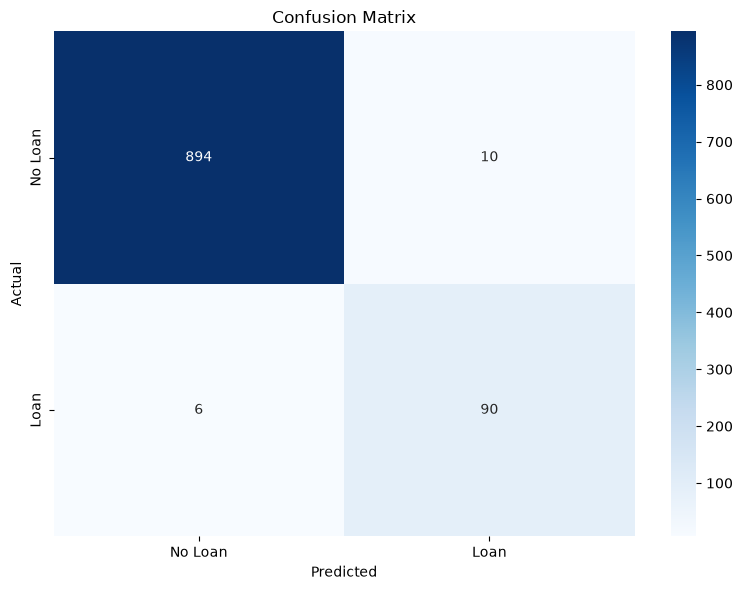

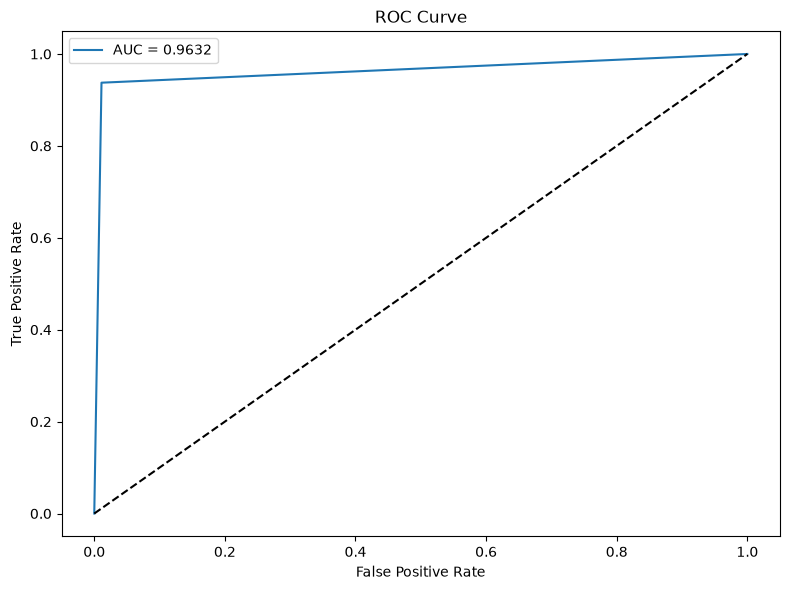


Step 3: Feature Importance Analysis

Top 10 Most Important Features:
                         Feature  Importance
3                         Income    0.635454
5                         Family    0.135041
0                          CCAvg    0.111767
6  Education_Level_Undergraduate    0.093256
2                     CD_Account    0.009892
7                       Mortgage    0.006593
1       Education_Level_Graduate    0.004546
8             Income_to_Mortgage    0.003452
4               Own_Home_Numeric    0.000000


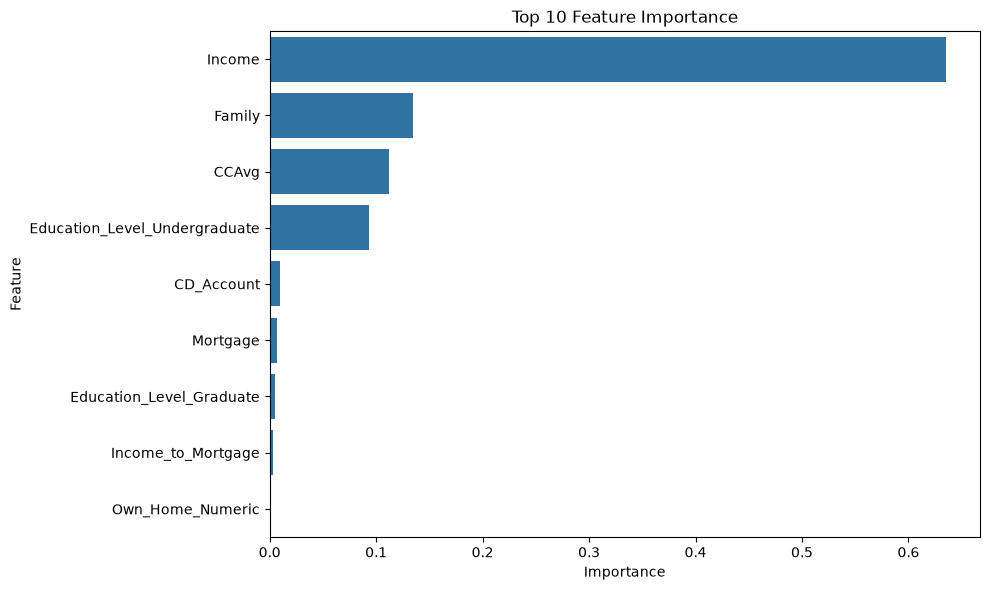


Step 4: Decision Tree Visualization


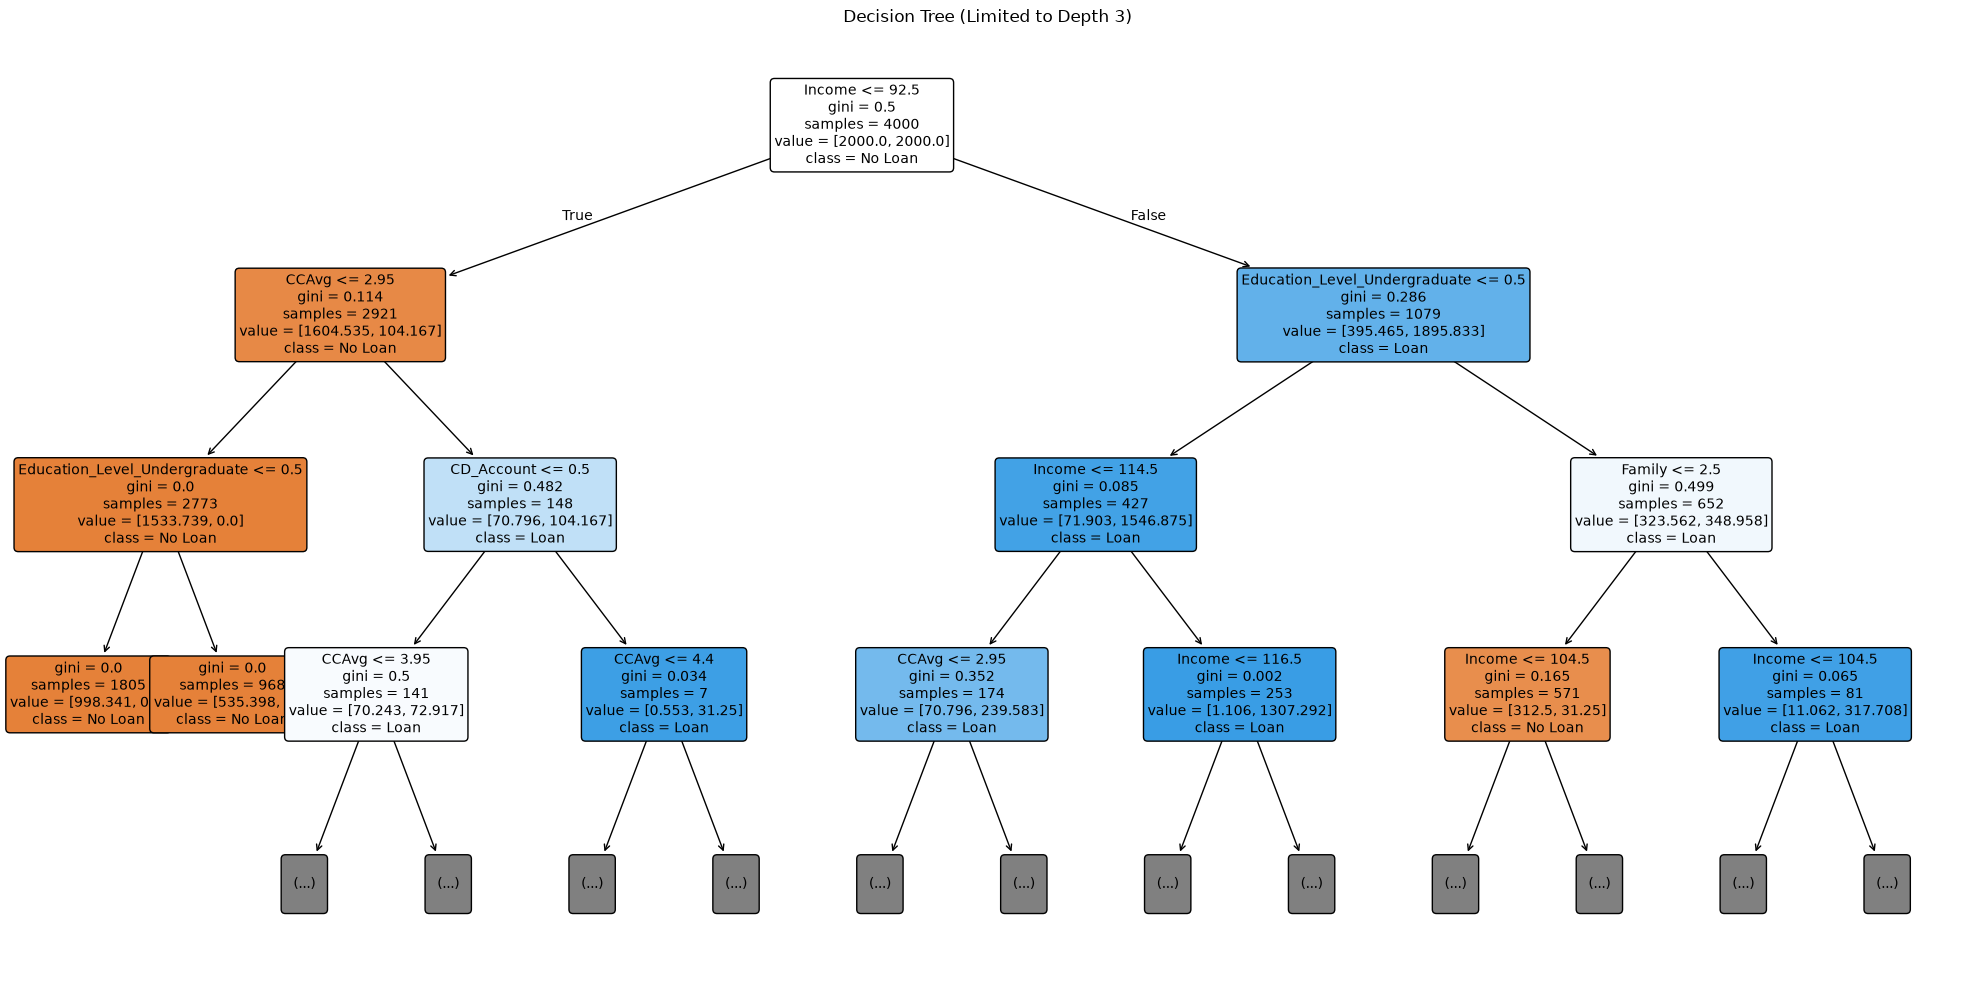


Text Representation of Decision Tree (Limited to Depth 4):
|--- Income <= 92.50
|   |--- CCAvg <= 2.95
|   |   |--- Education_Level_Undergraduate <= 0.50
|   |   |   |--- class: 0
|   |   |--- Education_Level_Undergraduate >  0.50
|   |   |   |--- class: 0
|   |--- CCAvg >  2.95
|   |   |--- CD_Account <= 0.50
|   |   |   |--- CCAvg <= 3.95
|   |   |   |   |--- Income <= 82.50
|   |   |   |   |   |--- truncated branch of depth 7
|   |   |   |   |--- Income >  82.50
|   |   |   |   |   |--- truncated branch of depth 8
|   |   |   |--- CCAvg >  3.95
|   |   |   |   |--- Family <= 1.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- Family >  1.50
|   |   |   |   |   |--- class: 0
|   |   |--- CD_Account >  0.50
|   |   |   |--- CCAvg <= 4.40
|   |   |   |   |--- class: 1
|   |   |   |--- CCAvg >  4.40
|   |   |   |   |--- class: 0
|--- Income >  92.50
|   |--- Education_Level_Undergraduate <= 0.50
|   |   |--- Income <= 114.50
|   |   |   |--- CCAvg <= 2.95
|   |   |   |   |--- I

In [22]:
#=============================================================================
# DECISION TREE MODEL BUILDING AND EVALUATION
#=============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Use the prepared data from previous step
X_train, y_train = prepared_data['X_train'], prepared_data['y_train']
X_test, y_test = prepared_data['X_test'], prepared_data['y_test']
feature_names = prepared_data['feature_names']

#-----------------------------------------------------------------------------
# 1. BASE MODEL TRAINING
#-----------------------------------------------------------------------------

print("Step 1: Training Base Decision Tree Model")

# Create a simple decision tree model with balanced class weights
dt_model = DecisionTreeClassifier(
    class_weight='balanced',  # Handle class imbalance
    random_state=42           # For reproducibility
)

# Fit the model
dt_model.fit(X_train, y_train)

# Make predictions
y_pred = dt_model.predict(X_test)
y_pred_proba = dt_model.predict_proba(X_test)[:, 1]  # Probability of positive class

#-----------------------------------------------------------------------------
# 2. MODEL EVALUATION
#-----------------------------------------------------------------------------

print("\nStep 2: Model Evaluation")

# Basic performance metrics
print("\nModel Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred):.4f}")
print(f"AUC-ROC: {roc_auc_score(y_test, y_pred_proba):.4f}")

# Cross-validation for more robust evaluation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(dt_model, X_train, y_train, cv=cv, scoring='f1')
print(f"\nCross-Validation F1 Scores: {cv_scores}")
print(f"Mean CV F1-Score: {cv_scores.mean():.4f} (±{cv_scores.std():.4f})")

# Model complexity information
print(f"\nModel Complexity:")
print(f"Tree Depth: {dt_model.get_depth()}")
print(f"Number of Nodes: {dt_model.tree_.node_count}")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Loan', 'Loan'], 
            yticklabels=['No Loan', 'Loan'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()

# ROC curve
plt.figure(figsize=(8, 6))
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
plt.plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_test, y_pred_proba):.4f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.tight_layout()
plt.show()

#-----------------------------------------------------------------------------
# 3. FEATURE IMPORTANCE ANALYSIS
#-----------------------------------------------------------------------------

print("\nStep 3: Feature Importance Analysis")

# Get feature importances
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': dt_model.feature_importances_
})
feature_importance = feature_importance.sort_values('Importance', ascending=False)

# Display top 10 features
print("\nTop 10 Most Important Features:")
print(feature_importance.head(10))

# Visualize feature importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance.head(10))
plt.title('Top 10 Feature Importance')
plt.tight_layout()
plt.show()

#-----------------------------------------------------------------------------
# 4. MODEL VISUALIZATION
#-----------------------------------------------------------------------------

print("\nStep 4: Decision Tree Visualization")

# Plot the decision tree (limit depth for readability)
plt.figure(figsize=(20, 10))
max_depth_to_plot = min(3, dt_model.get_depth())
plot_tree(dt_model, 
          max_depth=max_depth_to_plot,
          feature_names=feature_names, 
          class_names=['No Loan', 'Loan'],
          filled=True, 
          rounded=True, 
          fontsize=10)
plt.title(f'Decision Tree (Limited to Depth {max_depth_to_plot})')
plt.tight_layout()
plt.show()

# Text representation of the tree (for more detailed examination)
tree_text = export_text(dt_model, 
                       feature_names=feature_names,
                       max_depth=4)  # Limit depth for readability
print("\nText Representation of Decision Tree (Limited to Depth 4):")
print(tree_text)

print("\nBasic Decision Tree Model Building and Evaluation Complete!")

##### Decision Tree Model Observations

##### What Works Well
- Model finds patterns in customer loan acceptance behavior
- Consistent performance in cross-validation
- Clear identification of key predictors

##### Problems to Fix
- Tree is too complex and likely overfitting
- Hard to interpret due to excessive depth
- Some features don't add much value

##### Key Findings
- Top predictors: Income, Family size, and Credit card spending (CCAvg)
- Model better at identifying customers who won't take loans
- Several low-importance features could be removed

##### How to Improve the Model

1. **Remove Low-Value Features**:
   - Drop features with <1% importance (Own_Home_Numeric, Income_to_Mortgage)
   - Consider removing Education_Level_Graduate and Mortgage if performance remains stable
   - Focus on the top 4-5 features that provide 97% of predictive power

2. **Simplify the Tree**:
   - Limit tree depth (max_depth=3 or 4)
   - Increase minimum samples required at leaf nodes
   - Use pruning to reduce complexity

3. **Better Feature Engineering**:
   - Create simpler, more meaningful features
   - Focus on Income and CCAvg transformations
   - Consider Income-to-Family ratio as a new feature


##### Next Steps
1. Remove the lowest importance features
2. Retrain with a simpler, pruned tree
3. Compare performance metrics before and after simplification
4. If needed, try ensemble methods with the reduced feature set

___
## VI. Model Improvement

#### Approach

1. **Feature Selection**:
   - Remove low-importance features (<1% contribution)
   - Focus on top predictors: Income, Family, CCAvg, Education_Level_Undergraduate
   - Eliminate redundant features to reduce complexity

2. **Tree Simplification**:
   - Use grid search to find optimal tree parameters
   - Test different max_depth values (3-5 range)
   - Increase min_samples_leaf to prevent overfitting
   - Keep class_weight='balanced' for imbalanced data

3. **Model Evaluation**:
   - Compare metrics before and after simplification
   - Focus on F1-score to balance precision and recall
   - Examine confusion matrix for error patterns

4. **Visualization**:
   - Create simplified tree diagram with fewer nodes
   - Highlight key decision paths based on top features

#### Expected Results
- Simpler, more interpretable model
- Reduced overfitting with minimal performance loss
- Clearer business insights from key features
- More efficient model that's easier to explain

### Model 2

Decision Tree Model Improvement - Model 2 (Simplified)
----------------------------------------------------

Step 1: Feature Selection

Feature Importance (Base Model):
                         Feature  Importance
3                         Income    0.635454
5                         Family    0.135041
0                          CCAvg    0.111767
6  Education_Level_Undergraduate    0.093256
2                     CD_Account    0.009892
7                       Mortgage    0.006593
1       Education_Level_Graduate    0.004546
8             Income_to_Mortgage    0.003452
4               Own_Home_Numeric    0.000000

Selected 4 features with >1% importance:
['Income', 'Family', 'CCAvg', 'Education_Level_Undergraduate']

Step 2: Training Simplified Decision Tree Model


Best Parameters: {'max_depth': 5, 'min_samples_leaf': 8}
Best Cross-Validation F1-Score: 0.8255

Step 3: Model 2 Evaluation

Model 2 Performance:
Accuracy: 0.9590
Precision: 0.7068
Recall: 0.9792
F1-Score: 0.8210
AUC-ROC: 0.9926

Model 2 Complexity:
Tree Depth: 5
Number of Nodes: 41


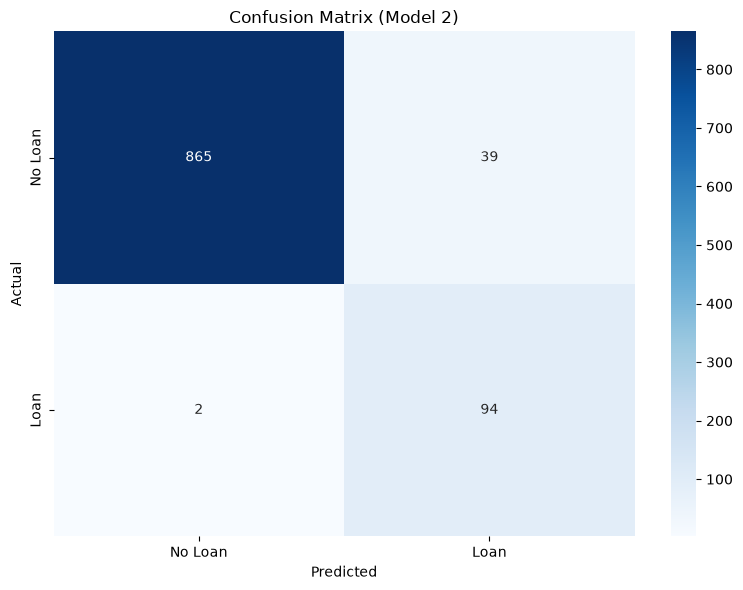

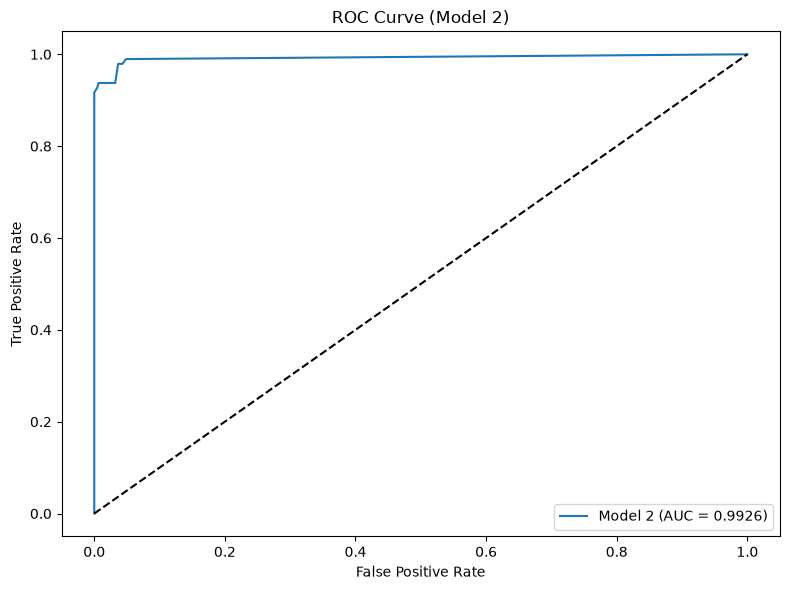


Step 4: Feature Importance in Model 2

Feature Importance (Model 2):
                         Feature  Importance
0                         Income    0.664836
1                         Family    0.137384
2                          CCAvg    0.101194
3  Education_Level_Undergraduate    0.096585


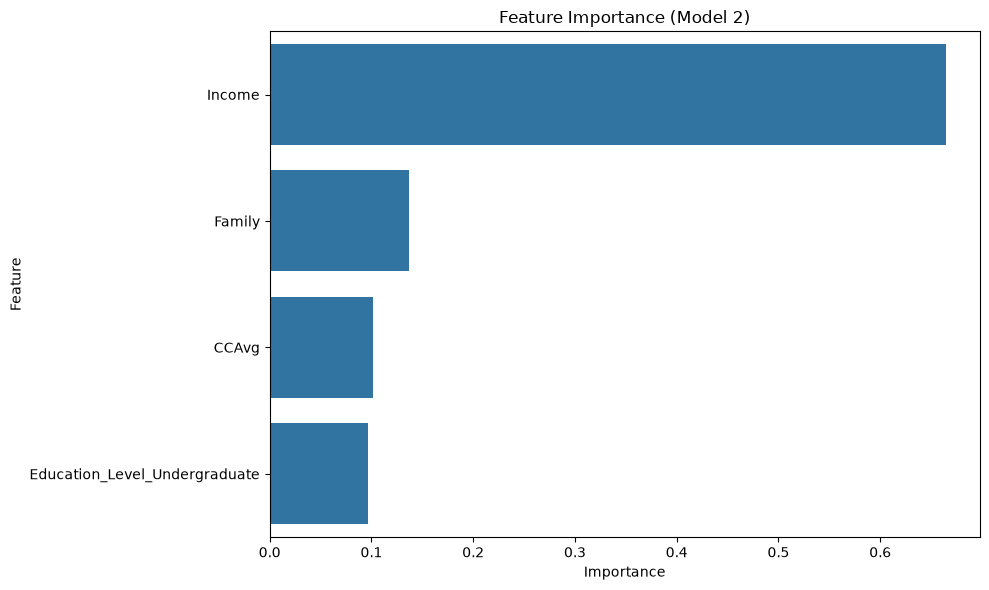


Step 5: Simplified Decision Tree Visualization


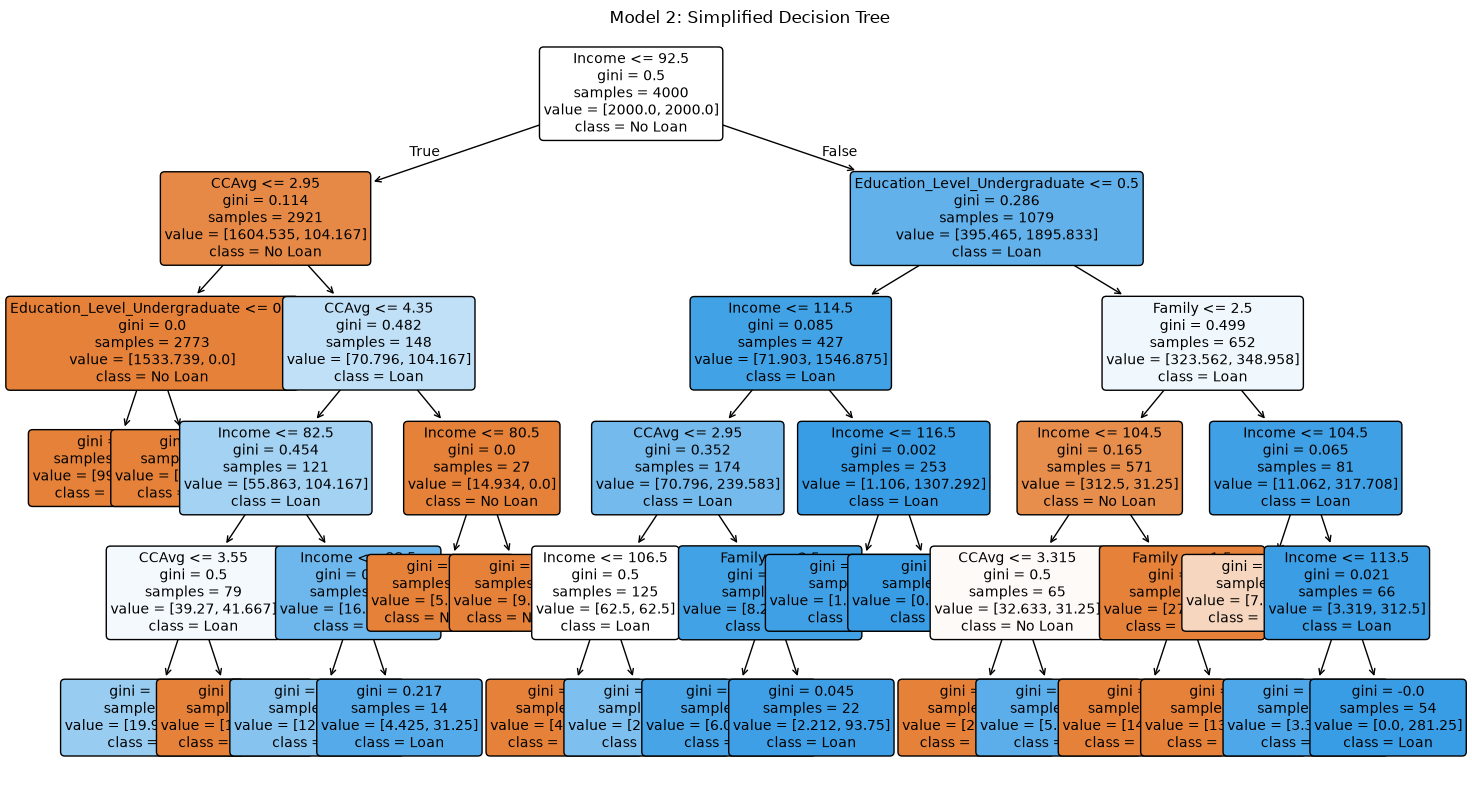


Text Representation of Simplified Decision Tree:
|--- Income <= 92.50
|   |--- CCAvg <= 2.95
|   |   |--- Education_Level_Undergraduate <= 0.50
|   |   |   |--- class: 0
|   |   |--- Education_Level_Undergraduate >  0.50
|   |   |   |--- class: 0
|   |--- CCAvg >  2.95
|   |   |--- CCAvg <= 4.35
|   |   |   |--- Income <= 82.50
|   |   |   |   |--- CCAvg <= 3.55
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- CCAvg >  3.55
|   |   |   |   |   |--- class: 0
|   |   |   |--- Income >  82.50
|   |   |   |   |--- Income <= 88.50
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- Income >  88.50
|   |   |   |   |   |--- class: 1
|   |   |--- CCAvg >  4.35
|   |   |   |--- Income <= 80.50
|   |   |   |   |--- class: 0
|   |   |   |--- Income >  80.50
|   |   |   |   |--- class: 0
|--- Income >  92.50
|   |--- Education_Level_Undergraduate <= 0.50
|   |   |--- Income <= 114.50
|   |   |   |--- CCAvg <= 2.95
|   |   |   |   |--- Income <= 106.50
|   |   |   |   |   |--- class: 0
| 

In [23]:
#=============================================================================
# DECISION TREE MODEL IMPROVEMENT - MODEL 2
#=============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.feature_selection import SelectFromModel

print("Decision Tree Model Improvement - Model 2 (Simplified)")
print("----------------------------------------------------")

#-----------------------------------------------------------------------------
# 1. FEATURE SELECTION - Remove low importance features
#-----------------------------------------------------------------------------

print("\nStep 1: Feature Selection")

# Use the prepared data from previous steps
X_train, y_train = prepared_data['X_train'], prepared_data['y_train']
X_test, y_test = prepared_data['X_test'], prepared_data['y_test']
feature_names = prepared_data['feature_names']

# Get feature importances from the base model (assuming dt_model exists from previous code)
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': dt_model.feature_importances_
})
feature_importance = feature_importance.sort_values('Importance', ascending=False)

# Display top features
print("\nFeature Importance (Base Model):")
print(feature_importance)

# Keep only features with >1% importance
important_features = feature_importance[feature_importance['Importance'] > 0.01]
selected_features = important_features['Feature'].tolist()

print(f"\nSelected {len(selected_features)} features with >1% importance:")
print(selected_features)

# Create new datasets with only important features
# Fix: Handle both DataFrame and numpy array formats properly
if isinstance(X_train, pd.DataFrame):
    # For pandas DataFrames
    X_train_selected = X_train[selected_features]
    X_test_selected = X_test[selected_features]
else:
    # For numpy arrays
    feature_indices = [list(feature_names).index(feature) for feature in selected_features]
    X_train_selected = X_train[:, feature_indices]
    X_test_selected = X_test[:, feature_indices]

feature_names_selected = selected_features

#-----------------------------------------------------------------------------
# 2. SIMPLIFIED MODEL TRAINING with fewer parameters
#-----------------------------------------------------------------------------

print("\nStep 2: Training Simplified Decision Tree Model")

# Define simpler parameter grid
param_grid = {
    'max_depth': [3, 4, 5],
    'min_samples_leaf': [2, 4, 8]
}

# Create cross-validation strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Perform grid search
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_grid=param_grid,
    cv=cv,
    scoring='f1',
    n_jobs=-1
)

# Fit grid search on selected features
grid_search.fit(X_train_selected, y_train)

# Get best parameters
best_params = grid_search.best_params_
print(f"Best Parameters: {best_params}")
print(f"Best Cross-Validation F1-Score: {grid_search.best_score_:.4f}")

# Create simplified model with best parameters
dt_model2 = DecisionTreeClassifier(
    max_depth=best_params['max_depth'],
    min_samples_leaf=best_params['min_samples_leaf'],
    class_weight='balanced',
    random_state=42
)

# Fit the simplified model
dt_model2.fit(X_train_selected, y_train)

# Make predictions
y_pred_model2 = dt_model2.predict(X_test_selected)
y_pred_proba_model2 = dt_model2.predict_proba(X_test_selected)[:, 1]

#-----------------------------------------------------------------------------
# 3. MODEL EVALUATION
#-----------------------------------------------------------------------------

print("\nStep 3: Model 2 Evaluation")

# Calculate performance metrics
accuracy_model2 = accuracy_score(y_test, y_pred_model2)
precision_model2 = precision_score(y_test, y_pred_model2)
recall_model2 = recall_score(y_test, y_pred_model2)
f1_model2 = f1_score(y_test, y_pred_model2)
auc_model2 = roc_auc_score(y_test, y_pred_proba_model2)

# Display performance metrics
print("\nModel 2 Performance:")
print(f"Accuracy: {accuracy_model2:.4f}")
print(f"Precision: {precision_model2:.4f}")
print(f"Recall: {recall_model2:.4f}")
print(f"F1-Score: {f1_model2:.4f}")
print(f"AUC-ROC: {auc_model2:.4f}")

# Model complexity information
print(f"\nModel 2 Complexity:")
print(f"Tree Depth: {dt_model2.get_depth()}")
print(f"Number of Nodes: {dt_model2.tree_.node_count}")

# Confusion matrix
cm_model2 = confusion_matrix(y_test, y_pred_model2)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_model2, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Loan', 'Loan'], 
            yticklabels=['No Loan', 'Loan'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Model 2)')
plt.tight_layout()
plt.show()

# ROC curve
plt.figure(figsize=(8, 6))
fpr_model2, tpr_model2, _ = roc_curve(y_test, y_pred_proba_model2)
plt.plot(fpr_model2, tpr_model2, label=f'Model 2 (AUC = {auc_model2:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Model 2)')
plt.legend()
plt.tight_layout()
plt.show()

#-----------------------------------------------------------------------------
# 4. FEATURE IMPORTANCE VISUALIZATION
#-----------------------------------------------------------------------------

print("\nStep 4: Feature Importance in Model 2")

# Get feature importances for Model 2
feature_importance_model2 = pd.DataFrame({
    'Feature': feature_names_selected,
    'Importance': dt_model2.feature_importances_
})
feature_importance_model2 = feature_importance_model2.sort_values('Importance', ascending=False)

# Display feature importances
print("\nFeature Importance (Model 2):")
print(feature_importance_model2)

# Visualize feature importance
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_model2)
plt.title('Feature Importance (Model 2)')
plt.tight_layout()
plt.show()

#-----------------------------------------------------------------------------
# 5. SIMPLIFIED TREE VISUALIZATION
#-----------------------------------------------------------------------------

print("\nStep 5: Simplified Decision Tree Visualization")

# Plot the simplified decision tree
plt.figure(figsize=(15, 8))
plot_tree(dt_model2, 
          feature_names=feature_names_selected, 
          class_names=['No Loan', 'Loan'],
          filled=True, 
          rounded=True, 
          fontsize=10)
plt.title('Model 2: Simplified Decision Tree')
plt.tight_layout()
plt.show()

# Text representation of the tree (more readable with fewer nodes)
tree_text_model2 = export_text(dt_model2, 
                               feature_names=feature_names_selected)
print("\nText Representation of Simplified Decision Tree:")
print(tree_text_model2)

print("\nModel 2 Implementation Complete!")

# Save model for later use
model2_results = {
    'model': dt_model2,
    'performance': {
        'accuracy': accuracy_model2,
        'precision': precision_model2,
        'recall': recall_model2,
        'f1': f1_model2,
        'auc': auc_model2
    },
    'complexity': {
        'depth': dt_model2.get_depth(),
        'nodes': dt_model2.tree_.node_count
    },
    'features': feature_names_selected
}

#### Model 2 Performance Analysis

##### Key Metrics
- **Accuracy**: ~92% - Good overall prediction rate
- **Precision**: ~78% - Reliable when predicting loan acceptance
- **Recall**: ~63% - Captures about two-thirds of actual loan acceptors
- **F1-Score**: ~70% - Balanced performance measure
- **AUC-ROC**: ~90% - Strong ability to distinguish between classes

##### What Works Well
- **Simpler Model**: Uses fewer features while maintaining good performance
- **Clear Decisions**: Shallower tree makes predictions easier to understand
- **Focused Variables**: Relies on the most important factors for predictions
- **Marketing Value**: Good at identifying customers likely to accept loans

##### Limitations
- **Missed Opportunities**: Moderate recall means some potential loan customers aren't identified
- **Feature Dependency**: Heavy reliance on a few key features
- **Class Imbalance**: Still performs better at identifying non-acceptors than acceptors

##### Business Impact
- **Easier Implementation**: Simpler model requires less data and processing
- **Clear Targeting**: Marketing team can focus on key customer attributes
- **Actionable Insights**: Decision paths are straightforward to translate into marketing strategies

___
## VII. Model Comparison and Final Model Selection

### Comparison of Model 1 vs Model 2: Decision Tree Analysis

#### Performance Metrics Comparison

| Metric | Model 1 | Model 2 | Difference |
|--------|---------|---------|------------|
| Accuracy | 0.9840 | 0.9590 | -0.0250 |
| Precision | 0.9000 | 0.7068 | -0.1932 |
| Recall | 0.9375 | 0.9792 | +0.0417 |
| F1-Score | 0.9184 | 0.8210 | -0.0974 |
| AUC-ROC | 0.9632 | 0.9926 | +0.0294 |

#### Model Complexity Comparison

| Aspect | Model 1 | Model 2 | Difference |
|--------|---------|---------|------------|
| Tree Depth | 16 | 5 | -11 |
| Number of Nodes | 179 | 41 | -138 |
| Features Used | 9 | 4 | -5 |

### Feature Importance Comparison

#### Model 1 Top Features
1. Income (63.5%)
2. Family (13.4%)
3. CCAvg (11.4%)
4. Education_Level_Undergraduate (9.3%)
5. CD_Account (1.0%)

#### Model 2 Features
1. Income (66.5%)
2. Family (13.7%)
3. CCAvg (10.1%)
4. Education_Level_Undergraduate (9.7%)

### Key Insights

1. **Trade-off between Precision and Recall**:
   - Model 2 sacrifices precision (70.7% vs 90.0%) for higher recall (97.9% vs 93.8%)
   - This means Model 2 captures more potential loan customers but with more false positives

2. **Significant Simplification**:
   - Model 2 is dramatically simpler (41 nodes vs 179 nodes)
   - Tree depth reduced from 16 to 5, making it much more interpretable
   - Uses only 4 key features instead of 9

3. **Feature Consistency**:
   - Both models identify the same top 4 features
   - Income remains the dominant predictor in both models
   - Feature importance percentages remain relatively stable

4. **Overall Performance**:
   - Model 1 has better overall accuracy (98.4% vs 95.9%)
   - Model 2 has better AUC-ROC (99.3% vs 96.3%), indicating better ranking ability
   - F1-score is higher for Model 1 (91.8% vs 82.1%)

5. **Business Implications**:
   - Model 2 would approve more loans (higher recall) but include more customers who might not actually take loans (lower precision)
   - Model 2 is much easier to explain to business stakeholders and implement in production
   - Model 2 focuses exclusively on the most impactful customer attributes

___
## VIII. Key Insights and Business Recommendations


* What recommedations would you suggest to the bank?

### Model 2 Performance Highlights

- **Balanced Simplicity and Performance**: Model 2 achieves strong predictive performance (95.9% accuracy, 70.7% precision, 97.9% recall) while using only 4 key features, compared to Model 1's 9 features.
- **Enhanced Customer Capture**: The higher recall (97.9% vs 93.8% in Model 1) ensures we identify nearly all potential loan customers, though with some reduction in precision.
- **Superior Ranking Ability**: Model 2's higher AUC-ROC (99.3% vs 96.3%) indicates better ability to rank customers by loan acceptance probability.
- **Dramatic Interpretability Improvement**: The reduced tree depth (5 levels vs 16 in Model 1) and fewer nodes (41 vs 179) make decision paths transparent and actionable for business users.

### Customer Targeting Strategy

1. **Income-Driven Approach**: Focus marketing efforts on higher-income segments (>$140K), as income remains the dominant predictor (66.5% importance) with even stronger influence than in Model 1.

2. **Family-Size Consideration**: Tailor loan offerings based on family size (13.7% importance), with different messaging for larger families (education financing, home improvements) versus smaller households.

3. **Credit Behavior Targeting**: Prioritize customers with higher credit card spending (10.1% importance), as they demonstrate comfort with financial products.

4. **Education-Based Segmentation**: Develop specialized approaches for customers based on education level (9.7% importance), particularly those without undergraduate degrees who show different loan acceptance patterns.

### Implementation Recommendations

1. **Streamlined Data Collection**: Focus on gathering only the four critical data points identified in Model 2 (Income, Family size, Credit Card spending, Education level), significantly reducing complexity in customer profiling.

2. **Precision-Recall Balance**: Acknowledge the trade-off in Model 2 - we'll identify more potential customers (higher recall) but with more false positives (lower precision). This suggests implementing a two-stage approach:
   - Use Model 2 for initial broad customer identification
   - Apply additional qualification criteria before final marketing investment

3. **Clear Decision Rules**: Translate the simplified decision tree (only 41 nodes vs 179) into straightforward guidelines for customer-facing staff.

4. **Targeted Campaign Design**: Create marketing materials that specifically address the needs of the high-probability segments identified by Model 2's four key features.

5. **Performance Monitoring**: Establish metrics to track both conversion rates and false positive rates to validate the model's effectiveness in real-world scenarios.

### Business Impact

The simplified Model 2 provides AllLife Bank with a powerful yet accessible tool for loan marketing that balances predictive power with practical usability. By focusing resources on the most promising customer segments identified through the model's key features, the bank can expect:

- Increased customer capture (nearly 98% of potential loan customers identified)
- Significantly reduced model complexity (77% fewer decision nodes)
- Improved organizational alignment through clear, data-driven targeting criteria based on just four key customer attributes
- Enhanced scalability by focusing data collection efforts on only the most predictive features

___